# 03 - Exploratory Data Analysis (EDA)
## Home Credit Default Risk · Credit Scoring Model

**Tujuan notebook ini:**
1. **Data profiling**: mengenal isi dan kelengkapan data
2. **Data quality check**: menemukan data yang janggal dan memutuskan cara menanganinya
3. **Analisis statistik**: memastikan pola yang terlihat benar-benar nyata, bukan kebetulan
4. **Business analysis**: menjawab pertanyaan bisnis untuk tim Credit Risk
5. **Justifikasi modeling**: membuktikan bahwa aturan sederhana tidak cukup, sehingga model diperlukan

Data yang dipakai adalah **data mart** hasil NB 02 (`mart_train`): 1 baris = 1 nasabah, sudah dilengkapi ringkasan riwayat kredit dari 7 tabel pendukung.

### Cara membaca notebook ini

| Istilah | Arti sederhana | Contoh |
|---|---|---|
| **Default / gagal bayar** | Nasabah yang terlambat membayar cicilan di awal masa pinjaman (`TARGET = 1`) | - |
| **Default rate** | Persentase nasabah yang gagal bayar dalam suatu kelompok | Default rate 12% = dari 100 nasabah, 12 orang gagal bayar |
| **Rata-rata (baseline) 8,1%** | Default rate **seluruh** nasabah. Ini **angka pembanding**: kelompok di atas 8,1% lebih berisiko dari rata-rata, di bawahnya lebih aman | Dari 100 nasabah Home Credit, rata-rata 8 orang gagal bayar |
| **Porsi** | Berapa persen kelompok itu dari seluruh nasabah | Porsi 4% = 4 dari 100 nasabah termasuk kelompok ini |
| **× rata-rata** | Seberapa kali lipat risiko kelompok dibanding rata-rata | 2× = risikonya dua kali lipat rata-rata |

Pada setiap grafik: **merah = lebih berisiko dari rata-rata**, **biru = lebih aman dari rata-rata**, dan **garis putus-putus = rata-rata 8,1%**.

Setiap grafik bisnis dilengkapi 4 bagian: **Yang terlihat**, **Cara membaca**, **Temuan**, dan **Action**.

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats

pd.set_option('display.max_columns', 60)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

# ---------- Gaya grafik: bersih, tanpa gridline ----------
NAVY, RED, BLUE, GREEN, INK, MUTED = '#1F3A5F', '#C8553D', '#4A7BA6', '#3E8E6E', '#2B2B2B', '#7A7A7A'
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'font.family': 'DejaVu Sans', 'font.size': 10, 'text.color': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left', 'axes.titlepad': 22,
    'axes.labelsize': 10, 'axes.labelcolor': INK, 'axes.edgecolor': '#BFBFBF',
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'xtick.color': INK, 'ytick.color': INK, 'legend.frameon': False})

PROCESSED_DIR = 'data/processed'
train = pd.read_parquet(f'{PROCESSED_DIR}/mart_train.parquet')
test  = pd.read_parquet(f'{PROCESSED_DIR}/mart_test.parquet')
for df in (train, test):                              # Int64 (nullable) dari BigQuery -> float
    int_cols = df.select_dtypes('Int64').columns
    df[int_cols] = df[int_cols].astype('float64')

BASELINE = train.TARGET.mean()
print(f'Train: {train.shape[0]:,} nasabah × {train.shape[1]} kolom  |  Test: {test.shape[0]:,} nasabah')
print(f'Rata-rata default rate (baseline): {BASELINE:.2%}')

Train: 307,511 nasabah × 146 kolom  |  Test: 48,744 nasabah
Rata-rata default rate (baseline): 8.07%


In [2]:
# ---------- Fungsi bantu ----------
fmt = lambda v, d=1: f'{v:,.{d}f}'.replace(',', '#').replace('.', ',').replace('#', '.')

def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, fontsize=9.5, color=MUTED, va='bottom')

def segment_table(df, col, order=None, min_n=0):
    t = df.groupby(col, observed=True).TARGET.agg(jumlah='count', default_rate='mean').reset_index()
    t = t[t.jumlah >= min_n]
    t['porsi_%'] = t.jumlah / len(df) * 100
    t['default_rate_%'] = t.default_rate * 100
    t['x_rata2'] = t.default_rate / BASELINE
    if order is not None:
        t[col] = pd.Categorical(t[col], categories=order, ordered=True); t = t.sort_values(col)
    return t.drop(columns='default_rate').reset_index(drop=True)

def plot_rate(t, col, title, sub, xlabel, horizontal=False, sort=False, ax=None, figsize=None):
    """Grafik default rate per segmen: label nilai + porsi, garis rata-rata, tanpa gridline."""
    if sort: t = t.sort_values('default_rate_%', ascending=horizontal)
    labels = t[col].astype(str).tolist(); vals = t['default_rate_%'].values; share = t['porsi_%'].values
    colors = [RED if v > BASELINE * 100 else BLUE for v in vals]
    if ax is None:
        figsize = figsize or ((9, 0.42 * len(t) + 1.6) if horizontal else (9, 4.2))
        fig, ax = plt.subplots(figsize=figsize)
    vmax = vals.max() * 1.28
    if horizontal:
        ax.barh(labels, vals, color=colors, height=0.62)
        ax.axvline(BASELINE * 100, color=NAVY, ls=(0, (4, 3)), lw=1)
        ax.text(BASELINE * 100, len(t) - 0.4, f' rata-rata {fmt(BASELINE*100)}%', color=NAVY, fontsize=8.5, va='bottom')
        for i, (v, s) in enumerate(zip(vals, share)):
            ax.text(v + vmax * 0.01, i, f'{fmt(v)}%', va='center', fontsize=9, fontweight='bold')
            ax.text(v + vmax * 0.01 + vmax * 0.085, i, f'({fmt(s)}% nasabah)', va='center', fontsize=8, color=MUTED)
        ax.set_xlim(0, vmax * 1.12); ax.set_xlabel('Default rate (%)'); ax.set_ylabel(xlabel)
        ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
    else:
        ax.bar(labels, vals, color=colors, width=0.62)
        ax.axhline(BASELINE * 100, color=NAVY, ls=(0, (4, 3)), lw=1)
        ax.text(len(t) - 0.5, BASELINE * 100, f'rata-rata {fmt(BASELINE*100)}%', color=NAVY, fontsize=8.5, ha='right', va='bottom')
        for i, (v, s) in enumerate(zip(vals, share)):
            ax.text(i, v + vmax * 0.015, f'{fmt(v)}%', ha='center', va='bottom', fontsize=9.5, fontweight='bold', bbox=dict(facecolor='white', edgecolor='none', pad=0.6))
            ax.text(i, vmax * 0.02, f'{fmt(s)}%\nnasabah', ha='center', va='bottom', fontsize=7.5, color='white')
        ax.set_ylim(0, vmax); ax.set_ylabel('Default rate (%)'); ax.set_xlabel(xlabel)
    ax.set_title(title); subtitle(ax, sub)
    return ax

def finish(): plt.tight_layout(); plt.show()

In [3]:
# Fitur bantu untuk analisis (versi resminya dibuat di NB 04)
train['AGE_YEARS']       = -train.DAYS_BIRTH / 365
train['EMPLOYED_YEARS']  = -train.DAYS_EMPLOYED.where(train.DAYS_EMPLOYED != 365243) / 365
train['EXT_SOURCE_MEAN'] = train[['EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3']].mean(axis=1)
train['ANNUITY_INCOME']  = train.AMT_ANNUITY / train.AMT_INCOME_TOTAL
train['CREDIT_INCOME']   = train.AMT_CREDIT / train.AMT_INCOME_TOTAL
train['CREDIT_GOODS']    = train.AMT_CREDIT / train.AMT_GOODS_PRICE
train['PHONE_CHANGE_YEARS'] = -train.DAYS_LAST_PHONE_CHANGE / 365

## 1. Data Profiling

### 1.1 Struktur data

In [4]:
profile = pd.DataFrame({'jumlah_nasabah': [len(train), len(test)],
                        'jumlah_kolom': [train.shape[1] - 7, test.shape[1]],
                        'memori_MB': [train.memory_usage(deep=True).sum()/1e6, test.memory_usage(deep=True).sum()/1e6]},
                       index=['mart_train (punya TARGET)', 'mart_test (tanpa TARGET)'])
display(profile.round(1))
print('Tipe data:', train.drop(columns=train.columns[-7:]).dtypes.astype(str).value_counts().to_dict())

,jumlah_nasabah,jumlah_kolom,memori_MB
mart_train (punya TARGET),307511,146,417.300
mart_test (tanpa TARGET),48744,145,63.000


Tipe data: {'float64': 130, 'str': 16}


**Penjelasan:** data latih berisi **307.511 nasabah** dengan 146 kolom (130 angka, 16 teks). Data test tidak memiliki kolom `TARGET` karena jawabannya belum diketahui. Itulah yang nanti diprediksi model.

### 1.2 Kamus fitur: 146 kolom dalam 11 kelompok

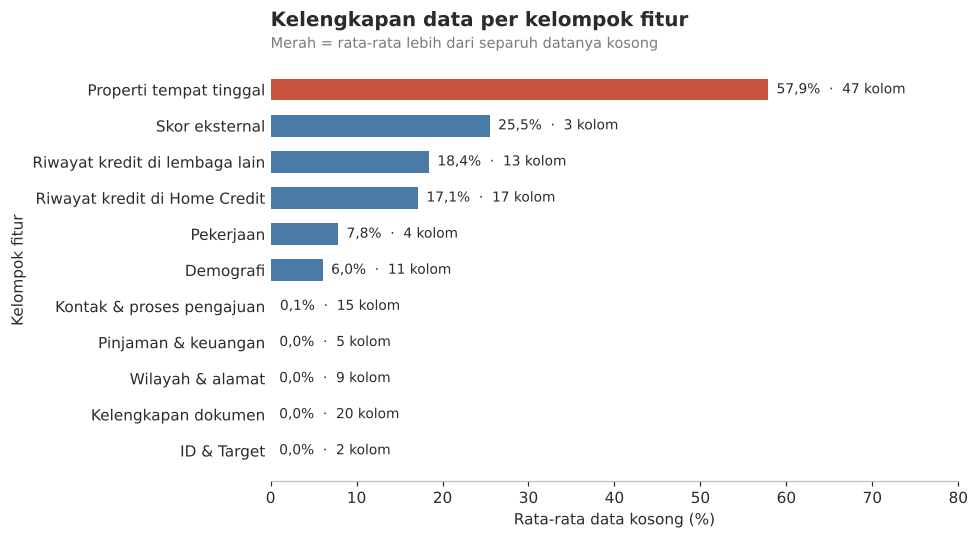

In [5]:
def feature_group(c):
    if c in ('SK_ID_CURR', 'TARGET'): return 'ID & Target'
    if c.startswith('BUREAU_') or c.startswith('AMT_REQ_CREDIT'): return 'Riwayat kredit di lembaga lain'
    if c.startswith(('PREV_', 'INST_', 'POS_', 'CC_')): return 'Riwayat kredit di Home Credit'
    if c.startswith('EXT_SOURCE'): return 'Skor eksternal'
    if c.startswith('FLAG_DOCUMENT'): return 'Kelengkapan dokumen'
    if c.startswith(('AMT_', 'NAME_CONTRACT')): return 'Pinjaman & keuangan'
    if any(k in c for k in ['_AVG', '_MODE', '_MEDI']): return 'Properti tempat tinggal'
    if c.startswith(('REGION_', 'REG_', 'LIVE_')): return 'Wilayah & alamat'
    if c in ('DAYS_EMPLOYED', 'OCCUPATION_TYPE', 'ORGANIZATION_TYPE', 'NAME_INCOME_TYPE'): return 'Pekerjaan'
    if c.startswith(('FLAG_', 'DAYS_LAST_PHONE')) or 'SOCIAL_CIRCLE' in c or 'APPR_PROCESS' in c: return 'Kontak & proses pengajuan'
    return 'Demografi'

orig_cols = [c for c in train.columns if c not in ('AGE_YEARS', 'EMPLOYED_YEARS', 'EXT_SOURCE_MEAN', 'ANNUITY_INCOME',
                                                   'CREDIT_INCOME', 'CREDIT_GOODS', 'PHONE_CHANGE_YEARS')]
groups = pd.Series({c: feature_group(c) for c in orig_cols})
miss = train[orig_cols].isna().mean() * 100
gs = (pd.DataFrame({'kelompok': groups, 'missing': miss}).groupby('kelompok')
        .agg(jumlah_kolom=('missing', 'size'), rata2_missing=('missing', 'mean')).sort_values('rata2_missing'))

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.barh(gs.index, gs.rata2_missing, color=[RED if v > 50 else BLUE for v in gs.rata2_missing], height=0.6)
for b, n, v in zip(bars, gs.jumlah_kolom, gs.rata2_missing):
    ax.text(v + 1, b.get_y() + b.get_height()/2, f'{fmt(v)}%  ·  {n} kolom', va='center', fontsize=9)
ax.set_xlim(0, 80); ax.set_xlabel('Rata-rata data kosong (%)'); ax.set_ylabel('Kelompok fitur')
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Kelengkapan data per kelompok fitur'); subtitle(ax, 'Merah = rata-rata lebih dari separuh datanya kosong')
finish()

**Yang terlihat:** rata-rata persentase data kosong (*missing value*) di setiap kelompok fitur, beserta jumlah kolomnya.

**Cara membaca:** makin panjang batang, makin banyak data yang kosong. Batang merah = rata-rata lebih dari separuh datanya kosong.

**Temuan:**
- Data inti (pinjaman, wilayah, dokumen, kontak) **hampir lengkap**.
- **Properti tempat tinggal** (47 kolom) rata-rata **58% kosong**, karena banyak nasabah tidak mengisi detail bangunan rumahnya.
- **Skor eksternal** kosong ±26% (terutama `EXT_SOURCE_1`), padahal kelompok ini nanti terbukti paling penting.
- Kekosongan di **riwayat kredit** bukan data hilang: nasabah memang tidak punya riwayat di tabel tersebut.

### 1.3 Kolom dengan data kosong terbanyak

In [6]:
miss_tbl = pd.DataFrame({'missing_%': miss, 'kelompok': groups}).query('`missing_%` > 0').sort_values('missing_%', ascending=False)
print(f'Kolom yang punya data kosong: {len(miss_tbl)} dari {len(orig_cols)}  |  kosong > 50%: {(miss_tbl["missing_%"] > 50).sum()} kolom')
miss_tbl.head(12).round(1)

Kolom yang punya data kosong: 91 dari 146  |  kosong > 50%: 45 kolom


,missing_%,kelompok
CC_UTILIZATION_MEAN,72.000,Riwayat kredit di Home Credit
CC_MONTHS_CNT,71.700,Riwayat kredit di Home Credit
CC_DPD_MAX,71.700,Riwayat kredit di Home Credit
BUREAU_WORST_STATUS,70.000,Riwayat kredit di lembaga lain
COMMONAREA_AVG,69.900,Properti tempat tinggal
COMMONAREA_MEDI,69.900,Properti tempat tinggal
COMMONAREA_MODE,69.900,Properti tempat tinggal
NONLIVINGAPARTMENTS_MEDI,69.400,Properti tempat tinggal
NONLIVINGAPARTMENTS_MODE,69.400,Properti tempat tinggal
NONLIVINGAPARTMENTS_AVG,69.400,Properti tempat tinggal


### 1.4 Keunikan, duplikat & jumlah kategori

In [7]:
print(f'Duplikat ID nasabah          : {train.SK_ID_CURR.duplicated().sum()}')
print(f'Duplikat baris (isi sama)     : {train[orig_cols].drop(columns="SK_ID_CURR").duplicated().sum()}')
print(f'ID yang ada di train & test   : {len(set(train.SK_ID_CURR) & set(test.SK_ID_CURR))}')

cat_cols = train.select_dtypes(['object', 'string']).columns.tolist()
card = pd.DataFrame({'jumlah_kategori': train[cat_cols].nunique(), 'kategori_terbanyak': train[cat_cols].mode().iloc[0],
                     'kosong_%': train[cat_cols].isna().mean() * 100}).sort_values('jumlah_kategori', ascending=False)
card.round(1)

Duplikat ID nasabah          : 0


Duplikat baris (isi sama)     : 0
ID yang ada di train & test   : 0


,jumlah_kategori,kategori_terbanyak,kosong_%
ORGANIZATION_TYPE,58,Business Entity Type 3,0.000
OCCUPATION_TYPE,18,Laborers,31.300
NAME_INCOME_TYPE,8,Working,0.000
NAME_TYPE_SUITE,7,Unaccompanied,0.400
WALLSMATERIAL_MODE,7,Panel,50.800
WEEKDAY_APPR_PROCESS_START,7,TUESDAY,0.000
NAME_FAMILY_STATUS,6,Married,0.000
NAME_HOUSING_TYPE,6,House / apartment,0.000
NAME_EDUCATION_TYPE,5,Secondary / secondary special,0.000
FONDKAPREMONT_MODE,4,reg oper account,68.400


**Penjelasan:** tidak ada nasabah ganda dan tidak ada nasabah yang muncul di train sekaligus test, sehingga data aman dari kebocoran. `ORGANIZATION_TYPE` punya 58 kategori (perlu penanganan khusus saat encoding di NB 04).

### 1.5 Distribusi target

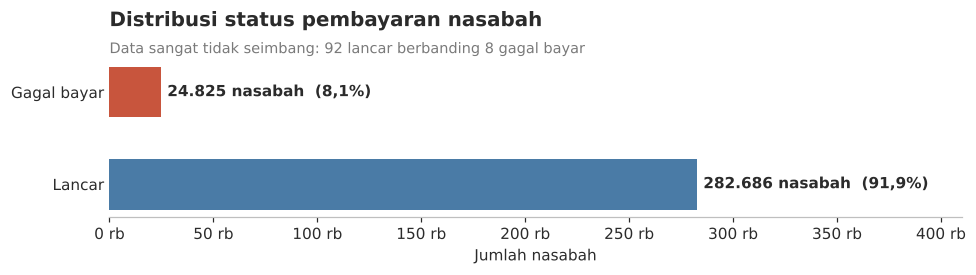

In [8]:
vc = train.TARGET.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.barh(['Lancar', 'Gagal bayar'], vc.values, color=[BLUE, RED], height=0.55)
for i, v in enumerate(vc.values):
    ax.text(v + 3000, i, f'{v:,}'.replace(',', '.') + f' nasabah  ({fmt(v/len(train)*100)}%)', va='center', fontweight='bold')
ax.set_xlim(0, vc.max() * 1.45); ax.set_xlabel('Jumlah nasabah'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x/1000:.0f} rb'))
ax.set_title('Distribusi status pembayaran nasabah'); subtitle(ax, 'Data sangat tidak seimbang: 92 lancar berbanding 8 gagal bayar')
finish()

**Yang terlihat:** jumlah nasabah lancar dan gagal bayar di data latih.

**Cara membaca:** panjang batang = jumlah nasabah; angka dalam kurung = persentasenya.

**Temuan:** dari 100 nasabah, **8 gagal bayar**. Inilah **rata-rata (baseline) 8,1%** yang dipakai sebagai pembanding di seluruh notebook.

**Dampak ke modeling:** karena gagal bayar jarang, model yang menebak "semua lancar" sudah benar 92%, tetapi tidak berguna. Itu sebabnya evaluasi memakai **PR-AUC dan F2-score**, bukan akurasi (lihat NB 01).

## 2. Data Quality Check

> **Catatan:** bagian ini **menemukan masalah dan memutuskan cara menanganinya**. Eksekusinya dilakukan di **NB 04** sebagai bagian dari *preprocessing pipeline*, agar langkah yang sama persis diterapkan ke data train, validasi, test, dan aplikasi Streamlit. Nilai pengisi (misalnya median) juga dihitung **hanya dari data train**, untuk mencegah kebocoran informasi (*data leakage*).

### 2.1 Nilai tidak masuk akal: `DAYS_EMPLOYED = 365243` (±1.000 tahun bekerja)

In [9]:
anom = train.DAYS_EMPLOYED == 365243
t = pd.DataFrame({'jumlah': [anom.sum(), (~anom).sum()],
                  'default_rate_%': [train.loc[anom, 'TARGET'].mean()*100, train.loc[~anom, 'TARGET'].mean()*100]},
                 index=['DAYS_EMPLOYED = 365243', 'Nilai normal'])
display(t.round(2))
print('Tipe pendapatan pada baris janggal:', train.loc[anom, 'NAME_INCOME_TYPE'].value_counts().to_dict())

,jumlah,default_rate_%
DAYS_EMPLOYED = 365243,55374,5.400
Nilai normal,252137,8.660


Tipe pendapatan pada baris janggal: {'Pensioner': 55352, 'Unemployed': 22}


**Temuan:** 55.374 nasabah (18%) memiliki nilai ini, dan **hampir semuanya pensiunan**. Jadi 365243 adalah **kode sistem untuk "tidak bekerja"**, bukan salah ketik. Default rate mereka (5,4%) bahkan lebih rendah dari rata-rata.

**Keputusan:** jangan dihapus (informasinya berharga). Ganti dengan kosong (NaN) dan buat penanda `IS_NOT_EMPLOYED = 1`.

### 2.2 Kategori tidak valid

In [10]:
for col, bad in [('CODE_GENDER', 'XNA'), ('NAME_FAMILY_STATUS', 'Unknown'), ('ORGANIZATION_TYPE', 'XNA')]:
    n = (train[col] == bad).sum()
    print(f'{col:<20} = {bad!r:<10}: {n:>7,} nasabah ({fmt(n/len(train)*100, 2)}%)')

CODE_GENDER          = 'XNA'     :       4 nasabah (0,00%)
NAME_FAMILY_STATUS   = 'Unknown' :       2 nasabah (0,00%)
ORGANIZATION_TYPE    = 'XNA'     :  55,374 nasabah (18,01%)


**Keputusan:**
- `CODE_GENDER = XNA` (4) dan `NAME_FAMILY_STATUS = Unknown` (2): sangat sedikit, diganti kategori terbanyak.
- `ORGANIZATION_TYPE = XNA`: jumlahnya **sama persis** dengan nasabah tidak bekerja (2.1), sehingga diganti menjadi kategori `Not employed`.

### 2.3 Outlier (nilai ekstrem)

In [11]:
num_check = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'CNT_CHILDREN', 'CNT_FAM_MEMBERS']
desc = train[num_check].describe(percentiles=[.01, .5, .99]).T
desc['max ÷ p99'] = desc['max'] / desc['99%']
desc[['min', '1%', '50%', '99%', 'max', 'max ÷ p99']].round(1)

,min,1%,50%,99%,max,max ÷ p99
AMT_INCOME_TOTAL,"25,650.000","45,000.000","147,150.000","472,500.000","117,000,000.000",247.600
AMT_CREDIT,"45,000.000","76,410.000","513,531.000","1,854,000.000","4,050,000.000",2.200
AMT_ANNUITY,"1,615.500","6,182.900","24,903.000","70,006.500","258,025.500",3.700
AMT_GOODS_PRICE,"40,500.000","67,500.000","450,000.000","1,800,000.000","4,050,000.000",2.200
CNT_CHILDREN,0.000,0.000,0.000,3.000,19.000,6.300
CNT_FAM_MEMBERS,1.000,1.000,2.000,5.000,20.000,4.000


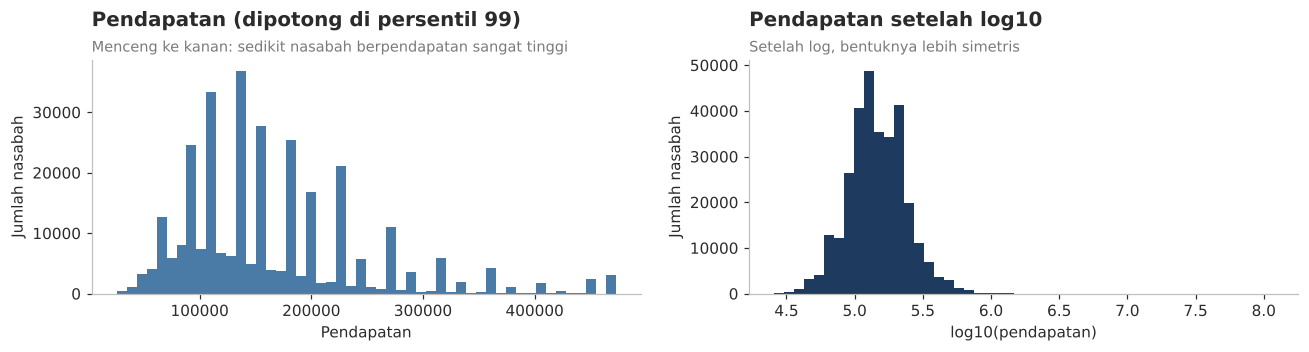

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.3))
inc = train.AMT_INCOME_TOTAL
axes[0].hist(inc.clip(upper=inc.quantile(.99)), bins=50, color=BLUE)
axes[0].set_title('Pendapatan (dipotong di persentil 99)'); axes[0].set_xlabel('Pendapatan'); axes[0].set_ylabel('Jumlah nasabah')
axes[1].hist(np.log10(inc), bins=50, color=NAVY)
axes[1].set_title('Pendapatan setelah log10'); axes[1].set_xlabel('log10(pendapatan)'); axes[1].set_ylabel('Jumlah nasabah')
subtitle(axes[0], 'Menceng ke kanan: sedikit nasabah berpendapatan sangat tinggi'); subtitle(axes[1], 'Setelah log, bentuknya lebih simetris')
finish()

**Cara membaca:** sumbu mendatar = besar pendapatan, tinggi batang = jumlah nasabah. Kiri: skala asli (nilai di atas persentil 99 dipotong agar terlihat). Kanan: skala log, yang "merapatkan" nilai besar sehingga bentuknya lebih simetris.

**Temuan:** pendapatan tertinggi 117 juta, **248× lipat** persentil 99. Distribusi pendapatan dan pinjaman **menceng ke kanan**: mayoritas di nilai kecil, segelintir sangat besar.

**Keputusan:** tidak dihapus. Untuk Logistic Regression dilakukan **log transform + pembatasan di persentil 99**, sedangkan model berbasis pohon (Random Forest, LightGBM) kebal terhadap outlier.

### 2.4 Konsistensi logika bisnis

In [13]:
checks = {
    'Umur < 18 tahun'                       : (train.AGE_YEARS < 18).sum(),
    'Jumlah anak > jumlah anggota keluarga' : (train.CNT_CHILDREN > train.CNT_FAM_MEMBERS).sum(),
    'Pinjaman < harga barang'               : (train.AMT_GOODS_PRICE > train.AMT_CREDIT).sum(),
    'Cicilan > pendapatan'                  : (train.AMT_ANNUITY > train.AMT_INCOME_TOTAL).sum(),
    'Tanggal (DAYS_*) di masa depan'        : (train[['DAYS_BIRTH', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH']] > 0).any(axis=1).sum()}
pd.Series(checks, name='jumlah_nasabah').to_frame()

,jumlah_nasabah
Umur < 18 tahun,0
Jumlah anak > jumlah anggota keluarga,0
Pinjaman < harga barang,260
Cicilan > pendapatan,33
Tanggal (DAYS_*) di masa depan,0


**Temuan:** tidak ada umur di bawah 18 tahun atau tanggal yang mustahil. *Pinjaman < harga barang* (260 kasus) wajar, karena sisanya dibayar dengan uang muka. *Cicilan > pendapatan* hanya 33 kasus, tapi patut diwaspadai.

### 2.5 Apakah data test mirip data train? (*data drift*)

In [14]:
drift_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'DAYS_BIRTH', 'DAYS_EMPLOYED',
              'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'PREV_CNT', 'BUREAU_CNT']
drift = pd.DataFrame([{'fitur': c, 'median_train': train[c].median(), 'median_test': test[c].median(),
                       'KS': stats.ks_2samp(train[c].dropna(), test[c].dropna()).statistic} for c in drift_cols])
drift['status'] = np.where(drift.KS > 0.1, 'sedikit berbeda', 'mirip')
display(drift.round(3))
pd.concat([train.NAME_CONTRACT_TYPE.value_counts(normalize=True).rename('train'),
           test.NAME_CONTRACT_TYPE.value_counts(normalize=True).rename('test')], axis=1).mul(100).round(1)

,fitur,median_train,median_test,KS,status
0,AMT_INCOME_TOTAL,"147,150.000","157,500.000",0.057,mirip
1,AMT_CREDIT,"513,531.000","450,000.000",0.116,sedikit berbeda
2,AMT_ANNUITY,"24,903.000","26,199.000",0.058,mirip
3,DAYS_BIRTH,"-15,750.000","-15,785.000",0.008,mirip
4,DAYS_EMPLOYED,"-1,213.000","-1,293.000",0.021,mirip
5,EXT_SOURCE_1,0.506,0.507,0.017,mirip
6,EXT_SOURCE_2,0.566,0.559,0.023,mirip
7,EXT_SOURCE_3,0.535,0.519,0.033,mirip
8,PREV_CNT,4.000,4.000,0.046,mirip
9,BUREAU_CNT,4.000,5.000,0.031,mirip


,train,test
NAME_CONTRACT_TYPE,,
Cash loans,90.500,99.100
Revolving loans,9.500,0.900


**Cara membaca:** nilai **KS** mengukur perbedaan sebaran data (0 = identik; di bawah 0,1 = mirip).

**Temuan:** hampir semua fitur mirip. Hanya `AMT_CREDIT` sedikit berbeda, karena data test **99% cash loan** (train 90,5%).

**Keputusan:** di NB 04, performa model juga dicek khusus untuk segmen cash loan.

### 2.6 Ringkasan keputusan data quality (dieksekusi di NB 04)

| Masalah | Temuan | Penanganan |
|---|---|---|
| `DAYS_EMPLOYED = 365243` | 18% data, mayoritas pensiunan | Jadikan kosong + penanda `IS_NOT_EMPLOYED` |
| `CODE_GENDER = XNA`, `FAMILY_STATUS = Unknown` | 6 nasabah | Isi kategori terbanyak |
| `ORGANIZATION_TYPE = XNA` | = nasabah tidak bekerja | Kategori `Not employed` |
| Outlier pendapatan & pinjaman | Menceng kanan | Log + batas persentil 99 (untuk LogReg) |
| Kolom kosong > 50% | 45 kolom (mayoritas properti) | Seleksi dengan IV & korelasi; penanda kosong untuk yang dipertahankan |
| Kosong di riwayat kredit | Memang tidak punya riwayat | Isi 0 untuk jumlah + penanda `HAS_BUREAU`, `HAS_CC` |
| Duplikat | Tidak ada | - |

## 3. Analisis Statistik

Tujuannya memastikan perbedaan antara nasabah lancar dan gagal bayar **benar-benar nyata**, bukan kebetulan, sekaligus mengukur **seberapa kuat** perbedaannya.

### 3.1 Perbandingan nilai tengah (median): nasabah lancar vs gagal bayar

In [15]:
key_num = ['EXT_SOURCE_MEAN', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'EMPLOYED_YEARS', 'AMT_INCOME_TOTAL',
           'AMT_CREDIT', 'ANNUITY_INCOME', 'CREDIT_INCOME', 'CREDIT_GOODS', 'PREV_REFUSED_RATE', 'INST_LATE_RATE',
           'BUREAU_ACTIVE_CNT', 'CC_UTILIZATION_MEAN', 'DEF_30_CNT_SOCIAL_CIRCLE', 'PHONE_CHANGE_YEARS']
desc_t = train.groupby('TARGET')[key_num].median().T
desc_t.columns = ['median_lancar', 'median_gagal_bayar']
desc_t['kemiringan (skewness)'] = train[key_num].skew()
desc_t.round(3)

,median_lancar,median_gagal_bayar,kemiringan (skewness)
EXT_SOURCE_MEAN,0.534,0.399,-0.530
EXT_SOURCE_2,0.574,0.440,-0.794
EXT_SOURCE_3,0.546,0.379,-0.409
AGE_YEARS,43.499,39.129,0.116
EMPLOYED_YEARS,4.633,3.370,1.968
AMT_INCOME_TOTAL,"148,500.000","135,000.000",391.560
AMT_CREDIT,"517,788.000","497,520.000",1.235
ANNUITY_INCOME,0.162,0.169,1.512
CREDIT_INCOME,3.267,3.253,1.836
CREDIT_GOODS,1.119,1.145,1.556


**Cara membaca:** median adalah nilai tengah. Jika median kelompok gagal bayar berbeda jauh dari kelompok lancar, fitur itu berpotensi membedakan keduanya. Skewness > 1 berarti datanya sangat menceng, sehingga uji statistik yang dipakai harus yang **tidak mengasumsikan data normal**.

### 3.2 Uji Mann-Whitney U (fitur angka)

- **Pertanyaan:** apakah sebaran nilai fitur pada nasabah gagal bayar **berbeda nyata** dari nasabah lancar?
- **Kenapa Mann-Whitney:** datanya tidak berdistribusi normal (lihat skewness), sehingga uji t tidak cocok.
- **Cara baca:** *p-value* < 0,05 berarti signifikan. Karena datanya 300 ribu baris, hampir semua akan signifikan, sehingga yang lebih penting adalah **effect size**: 0 = tidak membedakan sama sekali, 0,5 = membedakan sempurna.

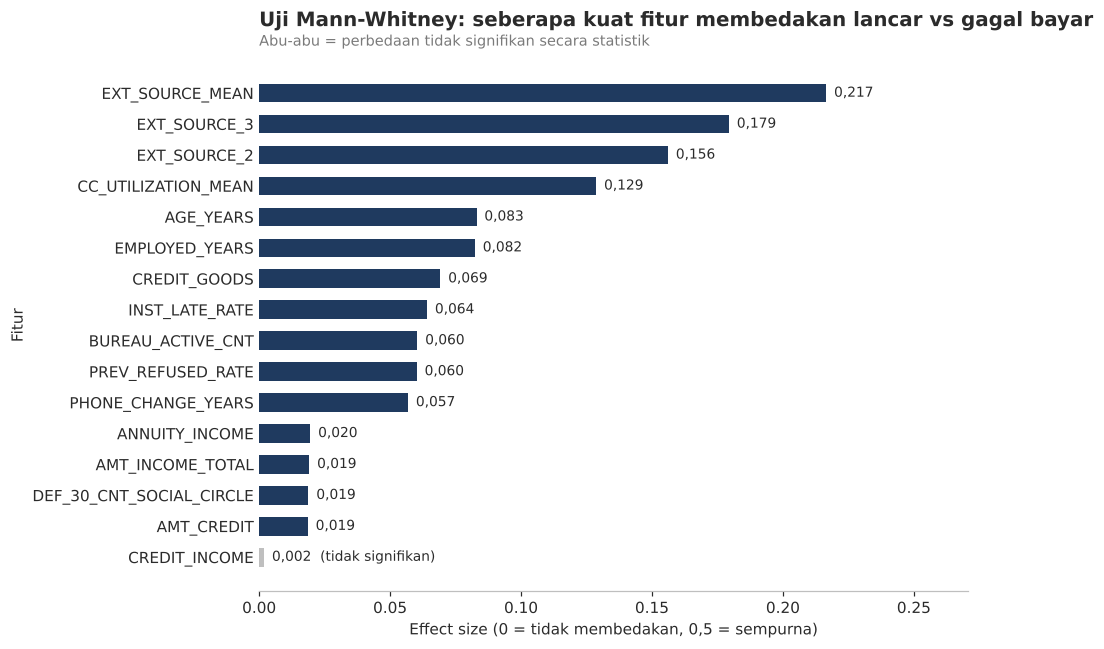

,fitur,p_value,"signifikan (p<0,05)",effect_size
15,EXT_SOURCE_MEAN,0.000,Ya,0.216
14,EXT_SOURCE_3,0.000,Ya,0.179
13,EXT_SOURCE_2,0.000,Ya,0.156
12,CC_UTILIZATION_MEAN,0.000,Ya,0.129
11,AGE_YEARS,0.000,Ya,0.083
10,EMPLOYED_YEARS,0.000,Ya,0.082
9,CREDIT_GOODS,0.000,Ya,0.069
8,INST_LATE_RATE,0.000,Ya,0.064
7,BUREAU_ACTIVE_CNT,0.000,Ya,0.060
6,PREV_REFUSED_RATE,0.000,Ya,0.060


In [16]:
mw = []
for c in key_num:
    a = train.loc[train.TARGET == 0, c].dropna(); b = train.loc[train.TARGET == 1, c].dropna()
    u, p = stats.mannwhitneyu(a, b)
    mw.append({'fitur': c, 'p_value': p, 'signifikan (p<0,05)': 'Ya' if p < 0.05 else 'Tidak',
               'effect_size': abs(u / (len(a) * len(b)) - 0.5)})
mw = pd.DataFrame(mw).sort_values('effect_size').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
cols = [NAVY if s == 'Ya' else '#BFBFBF' for s in mw['signifikan (p<0,05)']]
ax.barh(mw.fitur, mw.effect_size, color=cols, height=0.6)
for i, (v, s) in enumerate(zip(mw.effect_size, mw['signifikan (p<0,05)'])):
    ax.text(v + 0.003, i, fmt(v, 3) + ('' if s == 'Ya' else '  (tidak signifikan)'), va='center', fontsize=9)
ax.set_xlim(0, mw.effect_size.max() * 1.25); ax.set_xlabel('Effect size (0 = tidak membedakan, 0,5 = sempurna)')
ax.set_ylabel('Fitur'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Uji Mann-Whitney: seberapa kuat fitur membedakan lancar vs gagal bayar'); subtitle(ax, 'Abu-abu = perbedaan tidak signifikan secara statistik')
finish()
mw.sort_values('effect_size', ascending=False).round(4)

**Cara membaca grafik:** makin panjang batang, makin kuat fitur membedakan nasabah lancar dan gagal bayar. Batang abu-abu = tidak signifikan.

**Temuan:** **skor eksternal** paling kuat membedakan, jauh di atas fitur lain. Disusul utilisasi kartu kredit, usia, lama bekerja, rasio pinjaman terhadap harga barang, dan riwayat telat bayar. Rasio pinjaman/pendapatan (`CREDIT_INCOME`) **tidak signifikan**: besar pinjaman relatif terhadap gaji ternyata tidak membedakan nasabah lancar dan gagal bayar.

### 3.3 Uji Chi-square (fitur kategori)

- **Pertanyaan:** apakah default rate **berbeda nyata** antar kategori (misalnya antar jenis pekerjaan)?
- **Cara baca:** *p-value* < 0,05 = signifikan. Kekuatan hubungan diukur dengan **Cramér's V** (0 = tidak ada hubungan; < 0,1 lemah; 0,1-0,3 sedang).

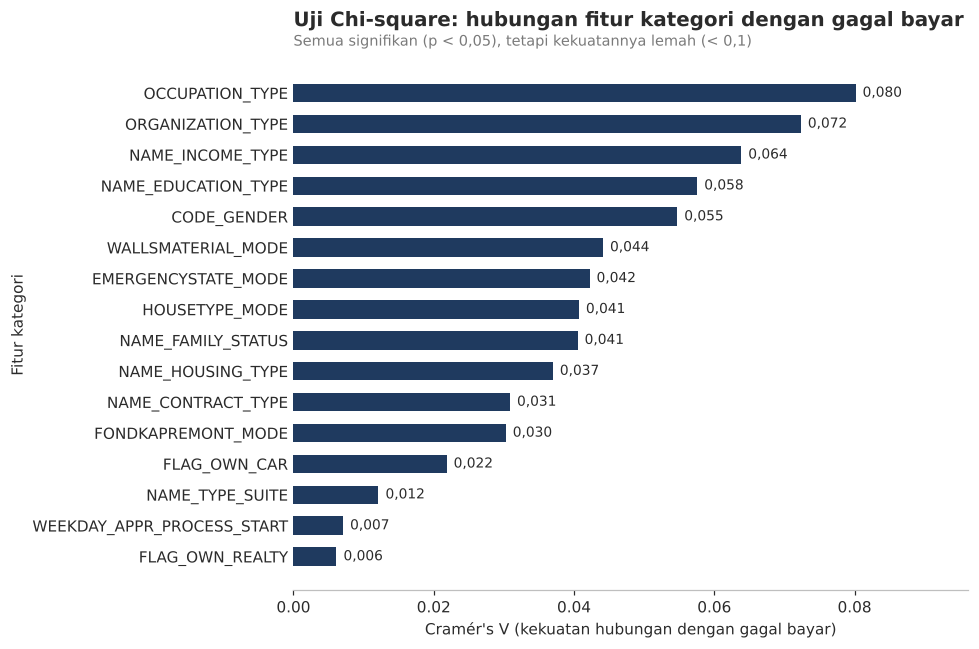

,fitur,chi2,derajat_bebas,p_value,"signifikan (p<0,05)",cramers_v
15,OCCUPATION_TYPE,"1,975.083",18,0.000,Ya,0.080
14,ORGANIZATION_TYPE,"1,609.241",57,0.000,Ya,0.072
13,NAME_INCOME_TYPE,"1,253.471",7,0.000,Ya,0.064
12,NAME_EDUCATION_TYPE,"1,019.213",4,0.000,Ya,0.058
11,CODE_GENDER,920.791,2,0.000,Ya,0.055
10,WALLSMATERIAL_MODE,599.041,7,0.000,Ya,0.044
9,EMERGENCYSTATE_MODE,547.976,2,0.000,Ya,0.042
8,HOUSETYPE_MODE,509.405,3,0.000,Ya,0.041
7,NAME_FAMILY_STATUS,504.694,5,0.000,Ya,0.041
6,NAME_HOUSING_TYPE,420.556,5,0.000,Ya,0.037


In [17]:
def cramers_v(x, y):
    ct = pd.crosstab(x, y); chi2, p, dof, _ = stats.chi2_contingency(ct)
    return chi2, p, dof, np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1)))

chi = []
for c in cat_cols:
    chi2, p, dof, v = cramers_v(train[c].fillna('Kosong'), train.TARGET)
    chi.append({'fitur': c, 'chi2': chi2, 'derajat_bebas': dof, 'p_value': p,
                'signifikan (p<0,05)': 'Ya' if p < 0.05 else 'Tidak', 'cramers_v': v})
chi = pd.DataFrame(chi).sort_values('cramers_v').reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(chi.fitur, chi.cramers_v, color=NAVY, height=0.6)
for i, v in enumerate(chi.cramers_v):
    ax.text(v + 0.001, i, fmt(v, 3), va='center', fontsize=9)
ax.set_xlim(0, chi.cramers_v.max() * 1.2); ax.set_xlabel("Cramér's V (kekuatan hubungan dengan gagal bayar)")
ax.set_ylabel('Fitur kategori'); ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Uji Chi-square: hubungan fitur kategori dengan gagal bayar'); subtitle(ax, 'Semua signifikan (p < 0,05), tetapi kekuatannya lemah (< 0,1)')
finish()
chi.sort_values('cramers_v', ascending=False).round(4)

**Cara membaca grafik:** makin panjang batang, makin kuat hubungan kategori tersebut dengan gagal bayar.

**Temuan:** semua fitur kategori **signifikan**, tetapi hubungannya **lemah** (Cramér's V < 0,1). Paling kuat: jenis pekerjaan, organisasi, tipe pendapatan, pendidikan, dan gender. Artinya **tidak ada satu kategori pun yang cukup untuk menentukan risiko sendirian**. Risiko harus dinilai dari kombinasi banyak fitur.

### 3.4 Korelasi setiap fitur dengan gagal bayar (plus / minus)

Sebelum melihat heatmap lengkap, grafik ini menunjukkan **arah** hubungan setiap fitur kunci dengan gagal bayar.

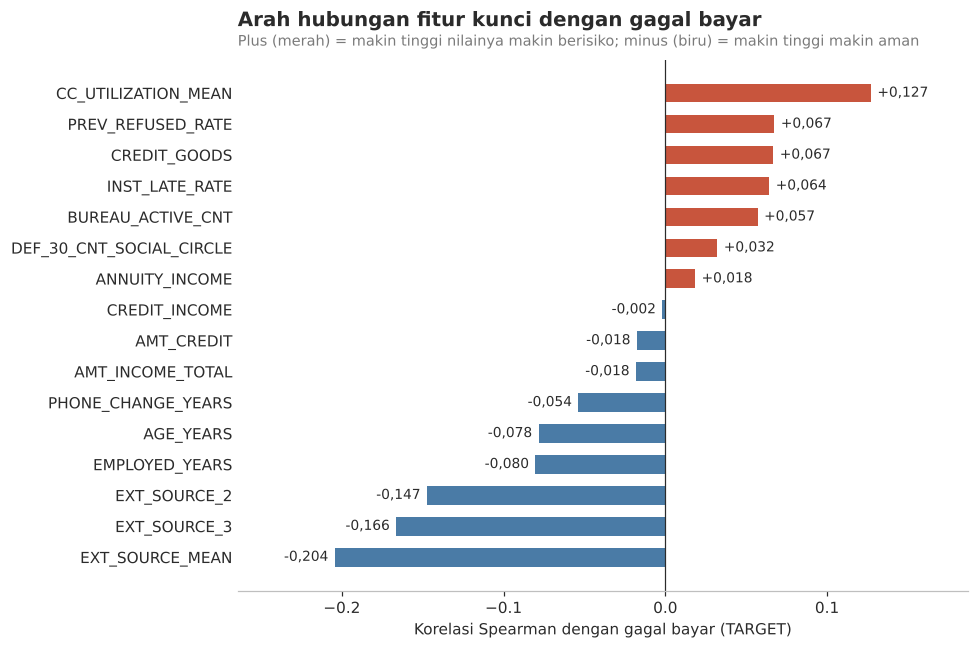

In [18]:
tc = train[key_num].corrwith(train.TARGET, method='spearman').sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(tc.index, tc.values, color=[BLUE if v < 0 else RED for v in tc.values], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
for i, v in enumerate(tc.values):
    ax.text(v + (0.004 if v >= 0 else -0.004), i, f'{"+" if v > 0 else ""}{fmt(v, 3)}', va='center',
            ha='left' if v >= 0 else 'right', fontsize=9)
ax.set_xlim(tc.min() - 0.06, tc.max() + 0.06); ax.set_xlabel('Korelasi Spearman dengan gagal bayar (TARGET)')
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Arah hubungan fitur kunci dengan gagal bayar')
subtitle(ax, 'Plus (merah) = makin tinggi nilainya makin berisiko; minus (biru) = makin tinggi makin aman')
finish()

**Cara membaca:** batang ke **kanan (plus, merah)** berarti makin besar nilai fitur, makin besar peluang gagal bayar. Batang ke **kiri (minus, biru)** berarti makin besar nilai fitur, makin kecil peluang gagal bayar. Makin panjang batang, makin kuat hubungannya.

**Temuan:** skor eksternal, usia, lama bekerja, dan lama sejak ganti nomor HP bernilai **minus** (faktor pelindung). Utilisasi kartu kredit, riwayat telat bayar, rasio pinjaman/harga barang, dan riwayat ditolak bernilai **plus** (faktor risiko). Semua nilainya kecil (di bawah 0,2), yang menegaskan bahwa **tidak ada satu fitur pun yang cukup sendirian**.

### 3.5 Heatmap korelasi

Korelasi mengukur seberapa searah dua fitur bergerak (-1 sampai +1). Dipakai **Spearman** karena data tidak normal. Heatmap ini menjawab dua pertanyaan:
1. **Fitur mana yang berkaitan dengan gagal bayar?** (baris `TARGET`)
2. **Fitur mana yang isinya mirip satu sama lain?** (korelasi tinggi = informasi ganda, berbahaya bagi Logistic Regression)

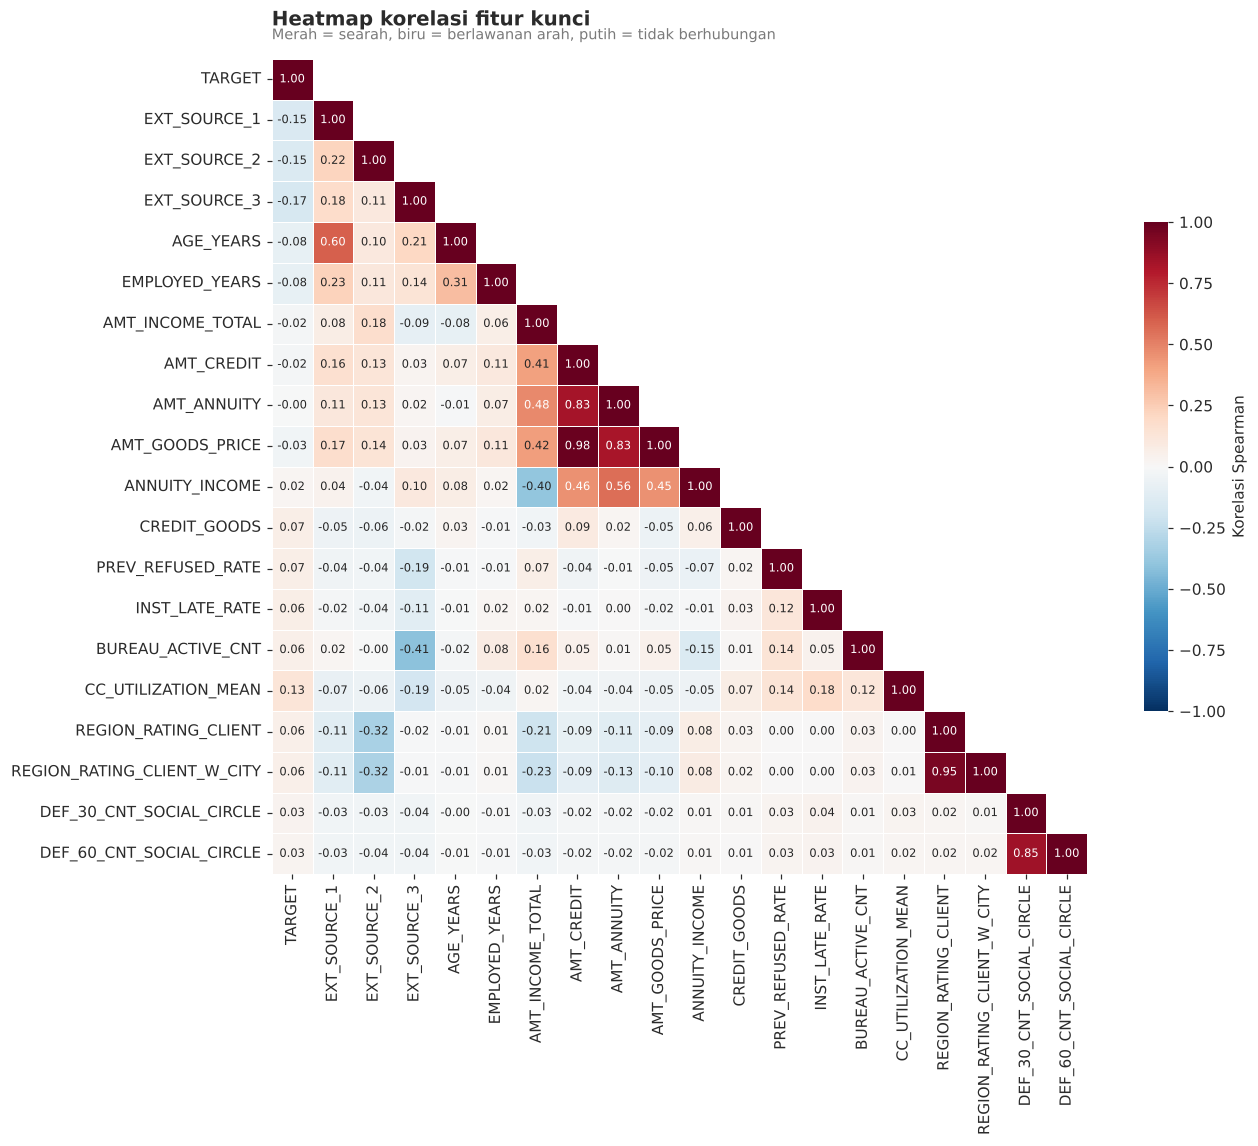

In [19]:
heat_cols = ['TARGET', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'EMPLOYED_YEARS',
             'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'ANNUITY_INCOME', 'CREDIT_GOODS',
             'PREV_REFUSED_RATE', 'INST_LATE_RATE', 'BUREAU_ACTIVE_CNT', 'CC_UTILIZATION_MEAN',
             'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE']
corr = train[heat_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(13, 10.5))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, vmin=-1, vmax=1, annot=True, fmt='.2f',
            annot_kws={'size': 7.5}, linewidths=0.6, linecolor='white', square=True,
            cbar_kws={'shrink': 0.6, 'label': 'Korelasi Spearman'}, ax=ax)
ax.set_title('Heatmap korelasi fitur kunci'); subtitle(ax, 'Merah = searah, biru = berlawanan arah, putih = tidak berhubungan')
finish()

**Cara membaca:** setiap kotak adalah korelasi antara fitur di baris dan kolomnya. Warna makin pekat = hubungan makin kuat.

**Temuan:**
- **Baris `TARGET`:** skor eksternal berkorelasi **negatif** (biru, makin tinggi skor makin kecil risiko gagal bayar). Riwayat telat bayar, utilisasi kartu kredit, dan rating wilayah berkorelasi **positif** (merah). Nilainya kecil (< 0,2), karena gagal bayar dipengaruhi banyak faktor sekaligus.
- **Informasi ganda:** `AMT_CREDIT`, `AMT_ANNUITY`, dan `AMT_GOODS_PRICE` berkorelasi sangat tinggi (≥ 0,8), begitu pula `REGION_RATING_CLIENT` dengan versi `_W_CITY` dan `DEF_30` dengan `DEF_60`.
- **Keputusan:** dari setiap pasangan dengan korelasi > 0,8, pertahankan **satu** saja (yang IV-nya lebih tinggi), terutama untuk Logistic Regression.

In [20]:
num_all = train[orig_cols].select_dtypes('number').drop(columns=['SK_ID_CURR', 'TARGET'])
c_all = num_all.corr(method='spearman').abs()
pairs = c_all.where(np.triu(np.ones(c_all.shape), k=1).astype(bool)).stack().reset_index()
pairs.columns = ['fitur_1', 'fitur_2', 'korelasi']; pairs = pairs.query('korelasi > 0.8').sort_values('korelasi', ascending=False)
print(f'Total pasangan fitur dengan korelasi > 0,8 (seluruh kolom): {len(pairs)}')
print(f'Di antaranya dari kolom properti (_AVG/_MODE/_MEDI): {pairs.fitur_1.str.contains("_AVG|_MODE|_MEDI").sum()}')
pairs.head(10).round(3)

Total pasangan fitur dengan korelasi > 0,8 (seluruh kolom): 111
Di antaranya dari kolom properti (_AVG/_MODE/_MEDI): 96


,fitur_1,fitur_2,korelasi
4285,YEARS_BUILD_AVG,YEARS_BUILD_MEDI,0.998
4156,YEARS_BEGINEXPLUATATION_AVG,YEARS_BEGINEXPLUATATION_MEDI,0.997
9419,OBS_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,0.997
5059,LANDAREA_AVG,LANDAREA_MEDI,0.996
4930,FLOORSMIN_AVG,FLOORSMIN_MEDI,0.996
5188,LIVINGAPARTMENTS_AVG,LIVINGAPARTMENTS_MEDI,0.996
4414,COMMONAREA_AVG,COMMONAREA_MEDI,0.996
5317,LIVINGAREA_AVG,LIVINGAREA_MEDI,0.996
3898,APARTMENTS_AVG,APARTMENTS_MEDI,0.995
4027,BASEMENTAREA_AVG,BASEMENTAREA_MEDI,0.995


### 3.6 Variance Inflation Factor (VIF)

Sesuai rancangan NB 01 (Bagian 9.3), multikolinearitas juga dicek dengan **VIF**: seberapa besar satu fitur bisa "ditebak" dari fitur lain. VIF > 10 berarti informasinya hampir seluruhnya ganda, sehingga koefisien Logistic Regression menjadi tidak stabil.

In [21]:
vif_cols = ['EXT_SOURCE_2', 'EXT_SOURCE_3', 'AGE_YEARS', 'EMPLOYED_YEARS', 'AMT_INCOME_TOTAL', 'AMT_CREDIT',
            'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'ANNUITY_INCOME', 'CREDIT_GOODS', 'REGION_RATING_CLIENT',
            'REGION_RATING_CLIENT_W_CITY', 'DEF_30_CNT_SOCIAL_CIRCLE', 'DEF_60_CNT_SOCIAL_CIRCLE']
X = train[vif_cols].dropna()
vif = pd.Series(np.diag(np.linalg.inv(X.corr().values)), index=vif_cols, name='VIF').sort_values(ascending=False)
vif.to_frame().assign(status=lambda d: np.where(d.VIF > 10, 'Tinggi (> 10)', np.where(d.VIF > 5, 'Waspada (5-10)', 'Aman'))).round(1)

,VIF,status
AMT_GOODS_PRICE,117.500,Tinggi (> 10)
AMT_CREDIT,115.300,Tinggi (> 10)
REGION_RATING_CLIENT_W_CITY,10.700,Tinggi (> 10)
REGION_RATING_CLIENT,10.700,Tinggi (> 10)
DEF_30_CNT_SOCIAL_CIRCLE,3.900,Aman
DEF_60_CNT_SOCIAL_CIRCLE,3.900,Aman
CREDIT_GOODS,3.200,Aman
AMT_ANNUITY,3.000,Aman
ANNUITY_INCOME,1.500,Aman
AGE_YEARS,1.200,Aman


**Cara membaca:** VIF 1 = tidak ada informasi ganda; 5 sampai 10 = perlu diwaspadai; di atas 10 = informasi ganda yang serius.

**Temuan:** `AMT_CREDIT` dan `AMT_GOODS_PRICE` memiliki VIF sangat tinggi karena nilainya hampir sama (pinjaman umumnya setara harga barang). Pasangan rating wilayah (`REGION_RATING_CLIENT` dan versi `_W_CITY`) juga tinggi (±10,7). Pasangan `DEF_30`/`DEF_60` masih aman menurut VIF (±3,9), meskipun korelasi Spearman-nya 0,85, karena sebagian besar nilainya nol.

**Keputusan:** untuk Logistic Regression, pertahankan satu dari setiap pasangan, misalnya `AMT_CREDIT` + rasio `CREDIT_GOODS` (tanpa `AMT_GOODS_PRICE`), dan `REGION_RATING_CLIENT_W_CITY`. Untuk `DEF_30`/`DEF_60`, cukup pertahankan `DEF_30` agar sederhana.

### 3.7 Information Value (IV): ranking kekuatan prediksi

IV adalah ukuran standar industri credit scoring (Siddiqi, 2017) untuk menilai **seberapa baik satu fitur memisahkan nasabah baik dan buruk**.

| IV | < 0,02 | 0,02-0,1 | 0,1-0,3 | 0,3-0,5 | > 0,5 |
|---|---|---|---|---|---|
| Kekuatan | Tidak berguna | Lemah | Sedang | Kuat | Sangat kuat |

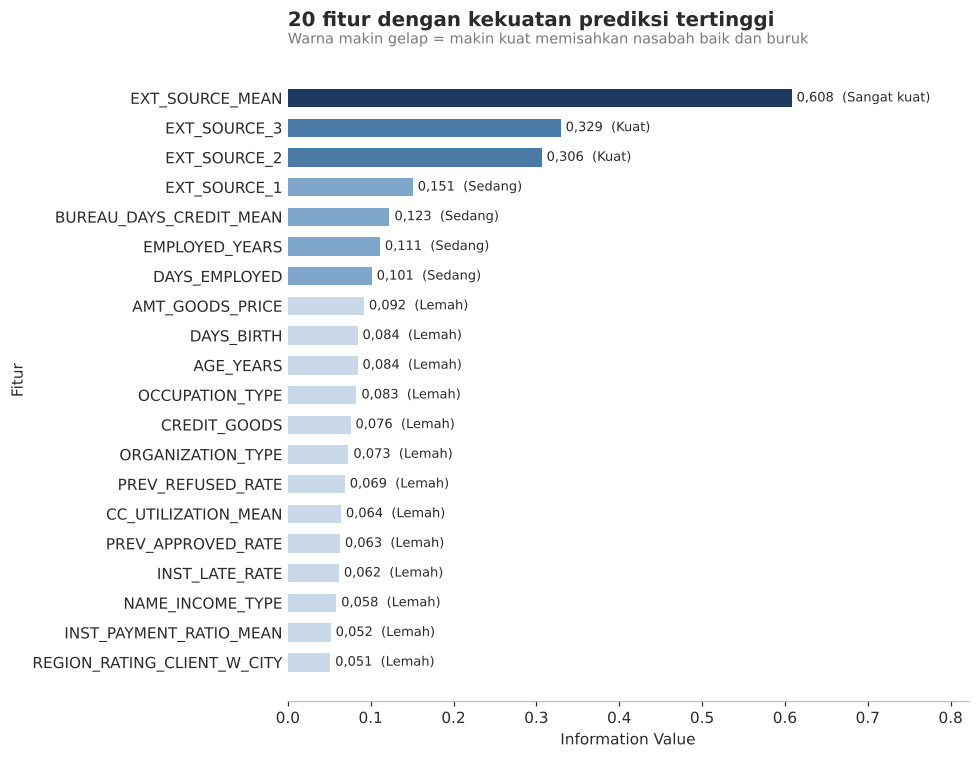

kekuatan
Tidak berguna    78
Lemah            66
Sedang            4
Kuat              2
Sangat kuat       1


In [22]:
def information_value(x, y, bins=10):
    df = pd.DataFrame({'x': x, 'y': y})
    df['bin'] = (pd.qcut(df.x, bins, duplicates='drop').astype(str)
                 if pd.api.types.is_numeric_dtype(df.x) and df.x.nunique() > bins else df.x.astype(str))
    df['bin'] = df.bin.where(df.x.notna(), 'Kosong')
    g = df.groupby('bin').y.agg(bad='sum', total='count'); g['good'] = g.total - g.bad
    db, dg = (g.bad + 0.5) / g.bad.sum(), (g.good + 0.5) / g.good.sum()
    return ((dg - db) * np.log(dg / db)).sum()

feat_cols = [c for c in train.columns if c not in ('SK_ID_CURR', 'TARGET')]
iv_tbl = pd.Series({c: information_value(train[c], train.TARGET) for c in feat_cols}, name='IV').sort_values(ascending=False).to_frame()
iv_tbl['kekuatan'] = pd.cut(iv_tbl.IV, [-1, 0.02, 0.1, 0.3, 0.5, 99], labels=['Tidak berguna', 'Lemah', 'Sedang', 'Kuat', 'Sangat kuat'])
iv_tbl['kelompok'] = [groups.get(c, 'Fitur turunan EDA') for c in iv_tbl.index]
iv_tbl.to_csv(f'{PROCESSED_DIR}/eda_information_value.csv')

top = iv_tbl.head(20).iloc[::-1]
pal = {'Sangat kuat': NAVY, 'Kuat': BLUE, 'Sedang': '#7FA7C9', 'Lemah': '#C9D9E8', 'Tidak berguna': '#E5E5E5'}
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top.index, top.IV, color=[pal[k] for k in top.kekuatan], height=0.62)
for i, (v, k) in enumerate(zip(top.IV, top.kekuatan)):
    ax.text(v + 0.006, i, f'{fmt(v, 3)}  ({k})', va='center', fontsize=8.5)
ax.set_xlim(0, top.IV.max() * 1.35); ax.set_xlabel('Information Value'); ax.set_ylabel('Fitur')
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('20 fitur dengan kekuatan prediksi tertinggi'); subtitle(ax, 'Warna makin gelap = makin kuat memisahkan nasabah baik dan buruk')
finish()
print(iv_tbl.kekuatan.value_counts().sort_index().to_string())

**Cara membaca:** makin panjang dan gelap batangnya, makin kuat fitur memisahkan nasabah baik dan buruk. Label di ujung batang = nilai IV dan kategorinya.

**Temuan:**
- **Skor eksternal mendominasi.** Rata-ratanya (`EXT_SOURCE_MEAN`) berkategori *sangat kuat* (IV 0,61). Ini wajar karena gabungan tiga skor, bukan *data leakage*.
- Berikutnya: usia kredit di bureau, lama bekerja, usia, pekerjaan, riwayat ditolak, utilisasi kartu kredit, dan riwayat telat bayar.
- Utilisasi kartu kredit kuat di uji Mann-Whitney tetapi IV-nya hanya *lemah*. Ini tidak bertentangan: Mann-Whitney hanya menghitung nasabah yang punya kartu kredit, sedangkan IV menghitung seluruh nasabah, padahal 72% di antaranya tidak punya kartu kredit. Artinya fitur ini **sangat informatif, tetapi hanya untuk sebagian kecil nasabah**.
- **±78 fitur berkategori "tidak berguna"** (IV < 0,02), mayoritas kolom properti dan dokumen. Kandidat kuat untuk dibuang di NB 04 agar model lebih ringan dan stabil.

## 4. Business Analysis

Pertanyaan bisnis disusun dari **7 hipotesis rancangan NB 01 (H1 sampai H7)**, ditambah beberapa analisis lanjutan. Setiap tambahan **memiliki alasan** dan tetap menjawab Objective 1 (profil nasabah berisiko dan action-nya bagi Credit Risk).

| Q | Pertanyaan | Sumber | Alasan (untuk analisis tambahan) |
|---|---|---|---|
| Q1 | Skor eksternal | Rancangan (H2) | - |
| Q2 | Konsentrasi gagal bayar per skor | Tambahan | Q1 menunjukkan skor sangat kuat; Q2 mengukur **berapa besar porsi risiko** yang bisa ditangani jika fokus pada skor rendah, sebagai dasar action yang terukur |
| Q3 | Usia | Rancangan (H1) | - |
| Q4 | Usia × skor eksternal | Tambahan | Memastikan usia bukan sekadar "bayangan" skor sebelum dijadikan dasar kebijakan, sekaligus aspek keadilan |
| Q5 | Beban cicilan / pendapatan | Rancangan (H3) | - |
| Q6 | Pinjaman vs harga barang | Tambahan | H3 terbukti lemah, sehingga dicari indikator kemampuan bayar lain; rasio ini signifikan di uji Mann-Whitney |
| Q7 | Lama bekerja | Rancangan (H5) | - |
| Q8 | Pekerjaan & sektor | Rancangan (H4) | - |
| Q9 | Pendidikan & sumber pendapatan | Rancangan (H4) | - |
| Q10 | Tempat tinggal & mobilitas | Tambahan | Pekerjaan stabil (H5) terbukti berpengaruh, sehingga diuji juga stabilitas tempat tinggal dan kontak, yang juga penting untuk proses penagihan |
| Q11 | Riwayat di Home Credit | Rancangan (H6) | - |
| Q12 | Utang di lembaga lain | Tambahan | H6 hanya mencakup riwayat di Home Credit; data Credit Bureau tersedia dari ETL (NB 02) dan mencakup 86% nasabah |
| Q13 | Pemakaian kartu kredit | Tambahan | Signifikan kuat di uji Mann-Whitney (peringkat 4) |
| Q14 | Nasabah tanpa riwayat kredit | Tambahan | Temuan cakupan data di NB 02 (14% tanpa riwayat bureau) dan relevan dengan misi Home Credit melayani nasabah *unbanked* |
| Q15 | Lingkungan sosial | Tambahan | Kolom tersedia di data utama dan menunjukkan pola bertingkat |
| Q16 | Rating wilayah | Rancangan (H7) | - |
| Q17 | Jenis kontrak & gender | Tambahan | Jenis kontrak: temuan drift di Bagian 2.5. Gender: signifikan di uji Chi-square, perlu disikapi dari sisi keadilan |

### A. Skor & Profil Risiko

#### Q1. Seberapa kuat skor eksternal membedakan nasabah? (H2)

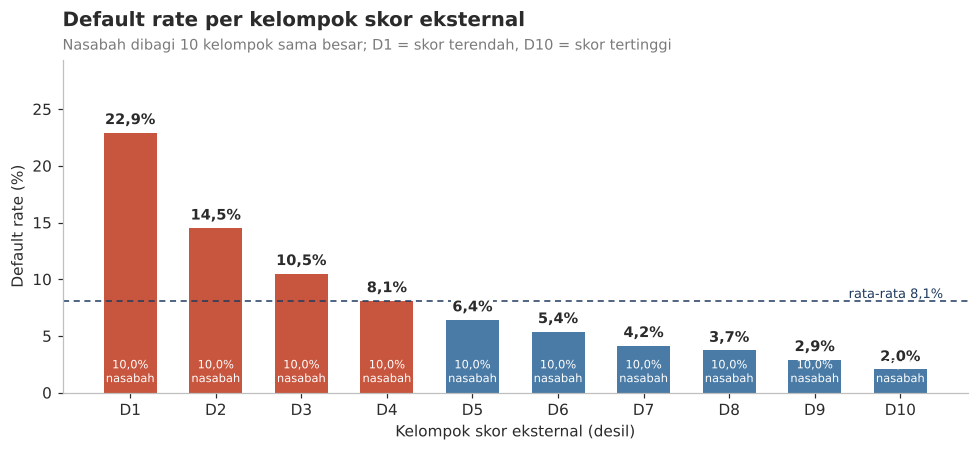

In [23]:
train['EXT_DECILE'] = pd.qcut(train.EXT_SOURCE_MEAN, 10, labels=[f'D{i}' for i in range(1, 11)])
t = segment_table(train, 'EXT_DECILE')
plot_rate(t, 'EXT_DECILE', 'Default rate per kelompok skor eksternal',
          'Nasabah dibagi 10 kelompok sama besar; D1 = skor terendah, D10 = skor tertinggi',
          'Kelompok skor eksternal (desil)'); finish()

**Yang terlihat:** nasabah diurutkan berdasarkan rata-rata skor eksternal (skor dari lembaga di luar Home Credit), lalu dibagi 10 kelompok sama besar (masing-masing 10% nasabah).

**Cara membaca:** tinggi batang = persentase gagal bayar di kelompok itu. Bandingkan dengan garis rata-rata 8,1%.

**Temuan:** risiko **turun tajam dan konsisten** seiring naiknya skor. Kelompok skor terendah (D1) gagal bayar **22,9%**, hampir **3× rata-rata**. Kelompok skor tertinggi (D10) hanya **2,0%**, atau **11× lebih aman** dari D1.

**Action:** jadikan skor eksternal pertimbangan utama saat menyaring pengajuan (lihat Q2 untuk cara memakainya).

#### Q2. Seberapa terkonsentrasi gagal bayar pada nasabah berskor rendah?

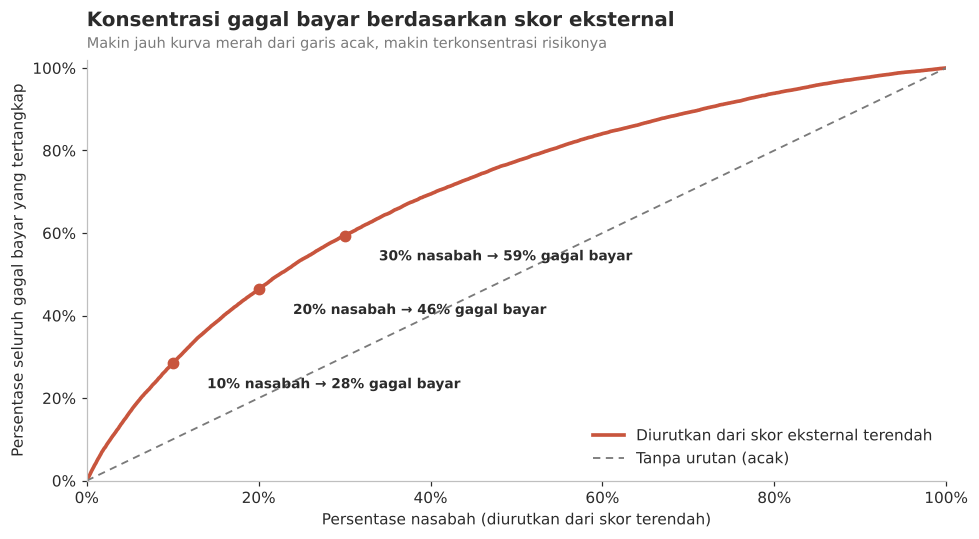

In [24]:
o = train[train.EXT_SOURCE_MEAN.notna()].sort_values('EXT_SOURCE_MEAN')
x = np.arange(1, len(o) + 1) / len(o) * 100
y = o.TARGET.cumsum().values / o.TARGET.sum() * 100

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, y, color=RED, lw=2.4, label='Diurutkan dari skor eksternal terendah')
ax.plot([0, 100], [0, 100], color=MUTED, lw=1.2, ls=(0, (4, 3)), label='Tanpa urutan (acak)')
for p in [10, 20, 30]:
    yv = y[int(len(o) * p / 100) - 1]
    ax.scatter(p, yv, color=RED, s=45, zorder=3)
    ax.annotate(f'{p}% nasabah → {fmt(yv, 0)}% gagal bayar', (p, yv), xytext=(p + 4, yv - 6), fontsize=9, fontweight='bold')
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_xlabel('Persentase nasabah (diurutkan dari skor terendah)'); ax.set_ylabel('Persentase seluruh gagal bayar yang tertangkap')
ax.set_title('Konsentrasi gagal bayar berdasarkan skor eksternal'); subtitle(ax, 'Makin jauh kurva merah dari garis acak, makin terkonsentrasi risikonya')
ax.legend(loc='lower right'); finish()

**Yang terlihat:** kurva kumulatif. Nasabah diurutkan dari skor terendah, lalu dihitung berapa persen dari **seluruh kasus gagal bayar** yang berada di kelompok tersebut.

**Cara membaca:** titik (20%, 46%) berarti *20% nasabah dengan skor terendah menyumbang 46% dari seluruh gagal bayar*. Garis putus-putus adalah kondisi jika skor tidak berguna (20% nasabah → 20% gagal bayar).

**Temuan:** gagal bayar **sangat terkonsentrasi**:
- **10%** nasabah berskor terendah → **28%** gagal bayar
- **20%** nasabah berskor terendah → **46%** gagal bayar (hampir separuh)
- **30%** nasabah berskor terendah → **59%** gagal bayar

**Action:** Credit Risk **tidak perlu memeriksa semua pengajuan secara mendalam**. Cukup fokuskan *review* manual (verifikasi dokumen, survei, wawancara) pada **20-30% pengajuan berskor terendah**, karena di situlah lebih dari separuh calon gagal bayar berada. Sumber daya analis jadi jauh lebih efisien.

#### Q3. Apakah usia memengaruhi risiko? (H1)

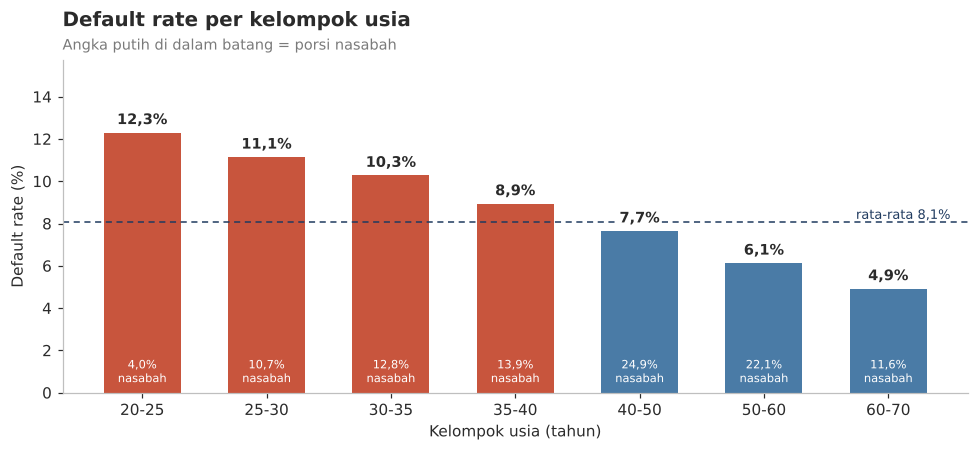

In [25]:
age_order = ['20-25', '25-30', '30-35', '35-40', '40-50', '50-60', '60-70']
train['AGE_GROUP'] = pd.cut(train.AGE_YEARS, [20, 25, 30, 35, 40, 50, 60, 70], labels=age_order)
t = segment_table(train, 'AGE_GROUP')
plot_rate(t, 'AGE_GROUP', 'Default rate per kelompok usia', 'Angka putih di dalam batang = porsi nasabah', 'Kelompok usia (tahun)'); finish()

**Yang terlihat:** persentase gagal bayar di setiap kelompok usia.

**Cara membaca:** batang merah = lebih berisiko dari rata-rata; angka putih = berapa persen nasabah ada di kelompok itu.

**Temuan:** risiko **turun konsisten seiring bertambahnya usia**. Usia 20-25 tahun gagal bayar **12,3%** (1,5× rata-rata), usia 60-70 tahun hanya **4,9%**. Nasabah di bawah 35 tahun mencakup ±27% pengajuan.

**Action:** lihat Q4. Usia **tidak boleh dipakai sendirian** untuk menolak.

#### Q4. Mana yang lebih menentukan: usia atau skor eksternal?

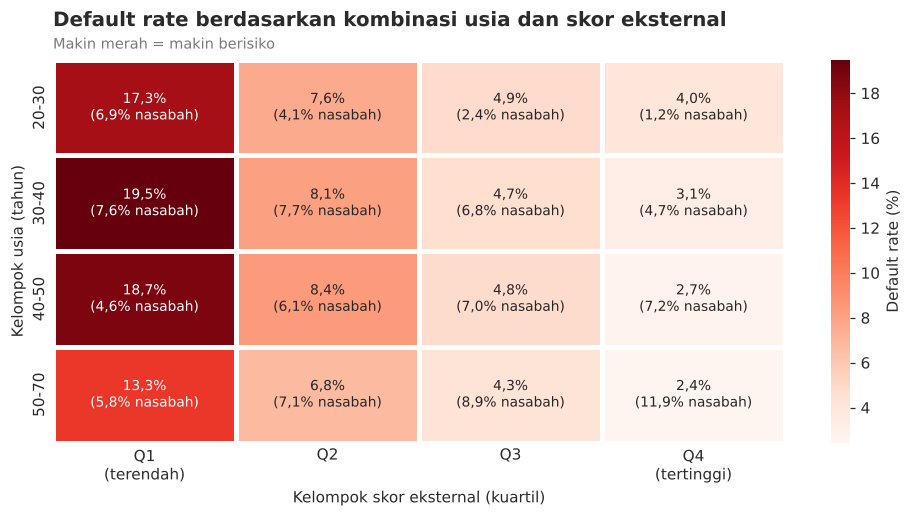

In [26]:
train['AGE_BAND'] = pd.cut(train.AGE_YEARS, [20, 30, 40, 50, 70], labels=['20-30', '30-40', '40-50', '50-70'])
train['EXT_Q'] = pd.qcut(train.EXT_SOURCE_MEAN, 4, labels=['Q1\n(terendah)', 'Q2', 'Q3', 'Q4\n(tertinggi)'])
pv = train.pivot_table('TARGET', 'AGE_BAND', 'EXT_Q', aggfunc='mean', observed=True) * 100
cnt = train.pivot_table('TARGET', 'AGE_BAND', 'EXT_Q', aggfunc='count', observed=True)
annot = pv.map(lambda v: f'{fmt(v)}%') + '\n' + (cnt / len(train) * 100).map(lambda v: f'({fmt(v)}% nasabah)')

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.heatmap(pv, annot=annot, fmt='', cmap='Reds', linewidths=2, linecolor='white',
            cbar_kws={'label': 'Default rate (%)'}, annot_kws={'fontsize': 9}, ax=ax)
ax.set_xlabel('Kelompok skor eksternal (kuartil)'); ax.set_ylabel('Kelompok usia (tahun)'); ax.tick_params(length=0)
ax.set_title('Default rate berdasarkan kombinasi usia dan skor eksternal'); subtitle(ax, 'Makin merah = makin berisiko')
finish()

**Yang terlihat:** default rate untuk setiap kombinasi kelompok usia (baris) dan kelompok skor eksternal (kolom).

**Cara membaca:** bandingkan warna **dari kiri ke kanan** (efek skor) dengan **dari atas ke bawah** (efek usia).

**Temuan:**
- **Skor jauh lebih menentukan daripada usia.** Di setiap kelompok usia, risiko turun drastis dari Q1 (±13-20%) ke Q4 (±2-4%).
- **Nasabah muda dengan skor tinggi justru lebih aman dari rata-rata** (usia 20-30 di Q4: ±4%, separuh dari rata-rata 8,1%). Sebaliknya, nasabah usia 30-50 dengan skor rendah justru paling berisiko (±19%).
- Nasabah muda **terlihat** berisiko karena mayoritas dari mereka memiliki skor rendah (riwayat kredit masih pendek), bukan karena usianya.

**Action:**
1. **Jangan menolak berdasarkan usia.** Selain tidak adil, simulasi di Bagian 5 membuktikan aturan "tolak usia < 25" justru **menaikkan** total biaya.
2. Untuk nasabah muda berskor rendah, berikan **limit awal kecil yang naik bertahap** jika lancar (*graduated limit*), agar mereka bisa membangun riwayat kredit.
3. Nasabah muda berskor tinggi adalah **segmen menarik untuk diakuisisi**: risikonya rendah dan potensi hubungan jangka panjangnya besar.

### B. Kemampuan Bayar

#### Q5. Apakah beban cicilan yang berat memicu gagal bayar? (H3)

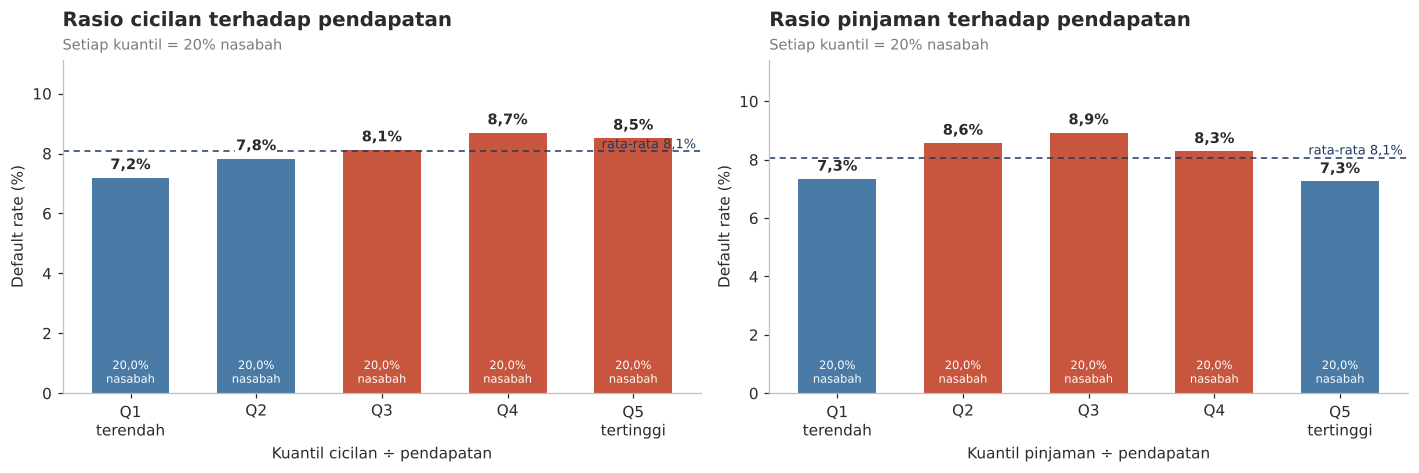

In [27]:
q_lbl = ['Q1\nterendah', 'Q2', 'Q3', 'Q4', 'Q5\ntertinggi']
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for ax, col, title, xl in [(axes[0], 'ANNUITY_INCOME', 'Rasio cicilan terhadap pendapatan', 'Kuantil cicilan ÷ pendapatan'),
                           (axes[1], 'CREDIT_INCOME', 'Rasio pinjaman terhadap pendapatan', 'Kuantil pinjaman ÷ pendapatan')]:
    train[col + '_Q'] = pd.qcut(train[col], 5, labels=q_lbl)
    plot_rate(segment_table(train, col + '_Q'), col + '_Q', title, 'Setiap kuantil = 20% nasabah', xl, ax=ax)
finish()

**Yang terlihat:** default rate menurut seberapa besar cicilan (kiri) dan pinjaman (kanan) dibanding pendapatan nasabah.

**Cara membaca:** Q1 = 20% nasabah dengan beban paling ringan, Q5 = paling berat.

**Temuan:** hipotesis H3 **hanya terbukti lemah**. Risiko naik dari 7,2% (Q1) ke ±8,5-8,7% (Q4-Q5) untuk rasio cicilan, sedangkan rasio pinjaman hampir tidak berpengaruh. Dugaan penyebabnya (belum dapat dibuktikan dari data): kebijakan persetujuan Home Credit sudah membatasi beban cicilan, sehingga nasabah dengan beban sangat berat sudah tersaring sejak awal. Data ini hanya berisi pinjaman yang **disetujui**.

**Action:** rasio cicilan **tidak cukup kuat dijadikan aturan tersendiri**. Rasio ini tetap dipakai sebagai fitur pelengkap di model.

#### Q6. Apakah pinjaman yang melebihi harga barang lebih berisiko?

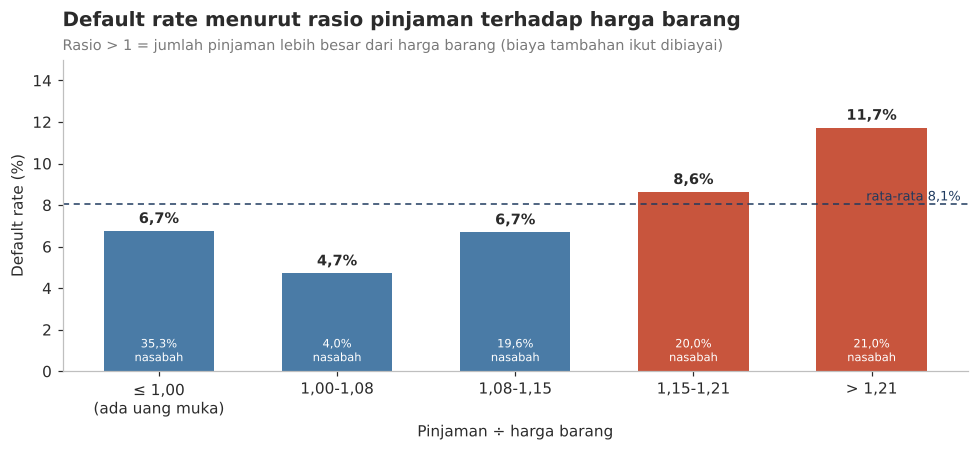

In [28]:
lbl = ['≤ 1,00\n(ada uang muka)', '1,00-1,08', '1,08-1,15', '1,15-1,21', '> 1,21']
train['CREDIT_GOODS_G'] = pd.cut(train.CREDIT_GOODS, [0, 1.0, 1.079, 1.145, 1.211, 10], labels=lbl)
t = segment_table(train, 'CREDIT_GOODS_G')
plot_rate(t, 'CREDIT_GOODS_G', 'Default rate menurut rasio pinjaman terhadap harga barang',
          'Rasio > 1 = jumlah pinjaman lebih besar dari harga barang (biaya tambahan ikut dibiayai)',
          'Pinjaman ÷ harga barang'); finish()

**Yang terlihat:** default rate menurut perbandingan jumlah pinjaman dengan harga barang yang dibeli.

**Cara membaca:** rasio 1,0 = pinjaman sama dengan harga barang. Rasio 1,2 = pinjaman 20% lebih besar dari harga barang (biaya asuransi, administrasi, dan lainnya ikut dipinjamkan). Rasio di bawah 1 = nasabah membayar uang muka.

**Temuan:** nasabah yang **meminjam lebih dari 21% di atas harga barang** gagal bayar **11,5%** (1,4× rata-rata), dan mencakup ±18% nasabah. Nasabah yang membayar uang muka hanya **6,7%**. Uang muka menunjukkan nasabah punya tabungan dan "ikut menanggung risiko".

**Action:**
1. Tawarkan **insentif uang muka** (misalnya bunga lebih rendah jika membayar DP ≥ 10%).
2. Batasi porsi biaya tambahan yang ikut dibiayai, terutama untuk nasabah berskor rendah.

### C. Stabilitas Hidup

#### Q7. Apakah lama bekerja berpengaruh? (H5)

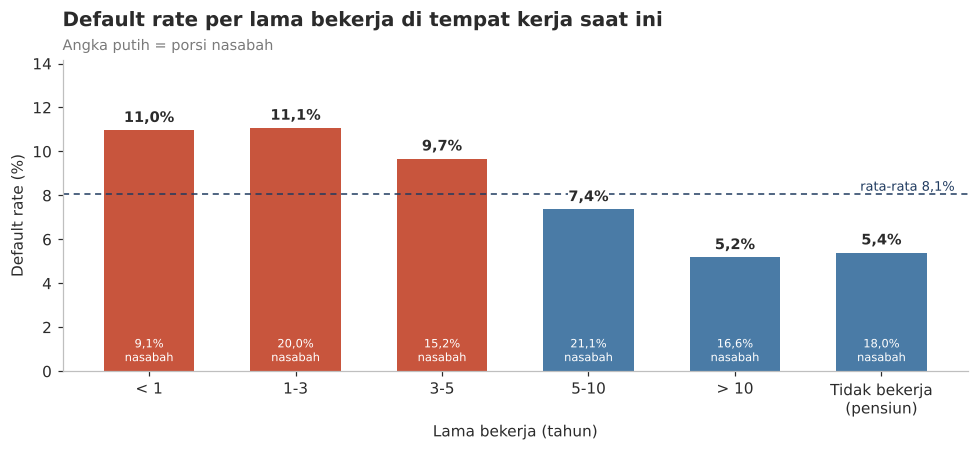

In [29]:
emp_order = ['< 1', '1-3', '3-5', '5-10', '> 10', 'Tidak bekerja\n(pensiun)']
train['EMP_GROUP'] = pd.cut(train.EMPLOYED_YEARS, [-0.01, 1, 3, 5, 10, 100], labels=emp_order[:-1]).astype(str)
train.loc[train.DAYS_EMPLOYED == 365243, 'EMP_GROUP'] = emp_order[-1]
t = segment_table(train, 'EMP_GROUP', order=emp_order)
plot_rate(t, 'EMP_GROUP', 'Default rate per lama bekerja di tempat kerja saat ini', 'Angka putih = porsi nasabah', 'Lama bekerja (tahun)'); finish()

**Yang terlihat:** default rate menurut lama nasabah bekerja di tempat kerja sekarang.

**Cara membaca:** batang merah = lebih berisiko dari rata-rata 8,1% (garis putus-putus), biru = lebih aman. Angka putih di dalam batang = porsi nasabah di kelompok itu.

**Temuan:** nasabah dengan masa kerja **< 3 tahun** paling berisiko (±11%, 1,4× rata-rata) dan jumlahnya cukup besar (±29% nasabah). Risiko turun seiring masa kerja, hingga **5,2%** untuk > 10 tahun. Pensiunan juga berisiko rendah (5,4%) karena memiliki penghasilan tetap. Ini sekaligus membuktikan bahwa data "365243" tidak boleh dibuang.

**Action:** untuk pemohon dengan masa kerja < 3 tahun, minta **bukti penghasilan tambahan** (slip gaji 3 bulan terakhir / kontrak kerja) sebelum persetujuan.

#### Q8. Pekerjaan dan sektor mana yang paling berisiko / aman? (H4)

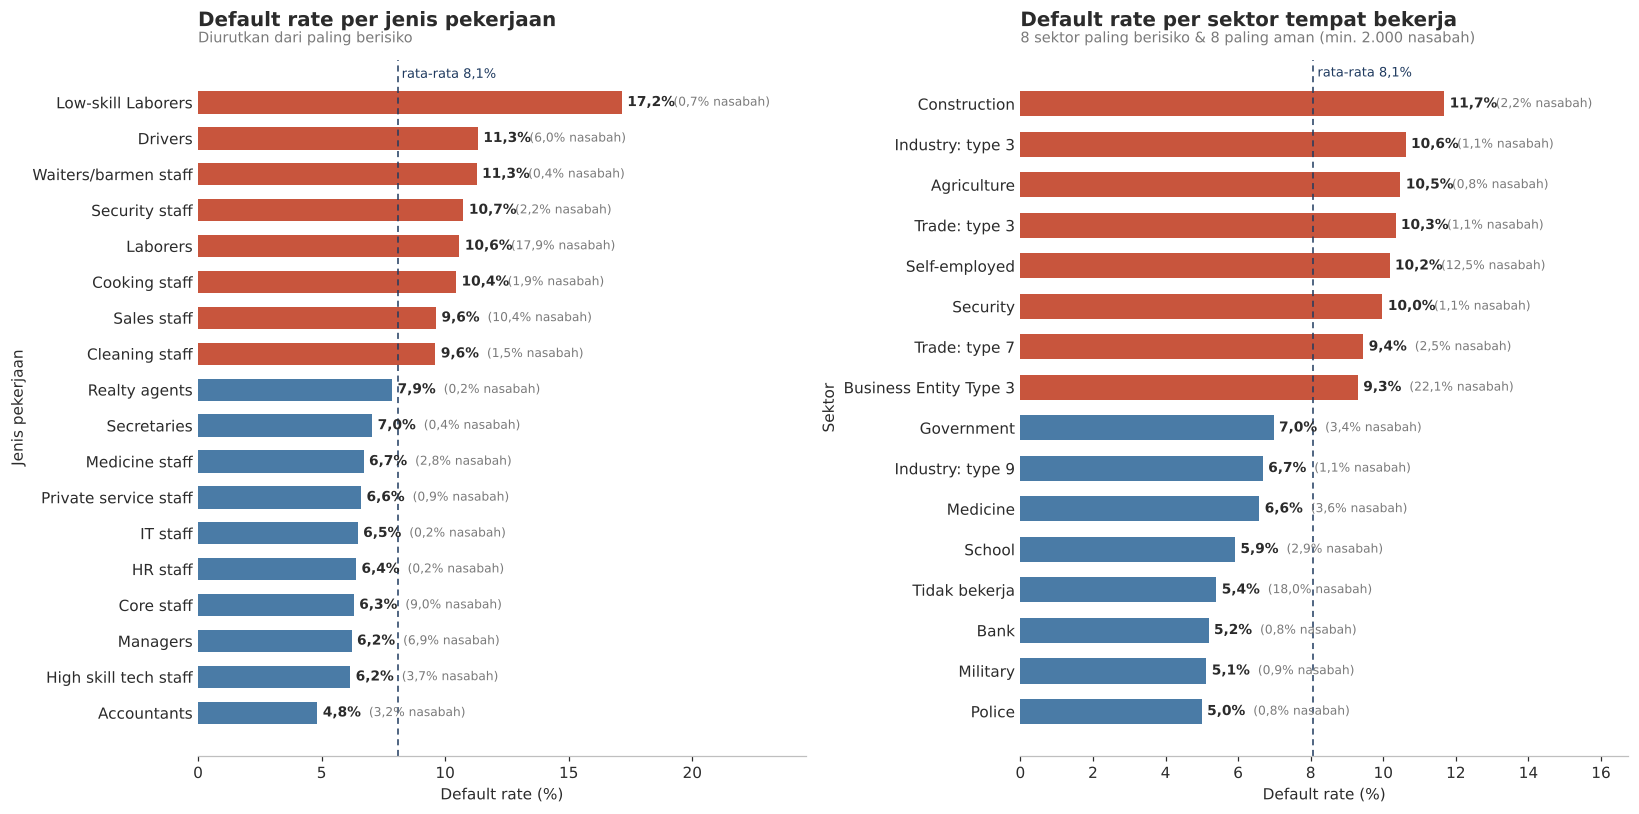

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7.5))
plot_rate(segment_table(train, 'OCCUPATION_TYPE'), 'OCCUPATION_TYPE', 'Default rate per jenis pekerjaan',
          'Diurutkan dari paling berisiko', 'Jenis pekerjaan', horizontal=True, sort=True, ax=axes[0])
org = segment_table(train.assign(ORGANIZATION_TYPE=train.ORGANIZATION_TYPE.replace('XNA', 'Tidak bekerja')),
                    'ORGANIZATION_TYPE', min_n=2000)
org = pd.concat([org.nlargest(8, 'default_rate_%'), org.nsmallest(8, 'default_rate_%')]).drop_duplicates()
plot_rate(org, 'ORGANIZATION_TYPE', 'Default rate per sektor tempat bekerja',
          '8 sektor paling berisiko & 8 paling aman (min. 2.000 nasabah)', 'Sektor', horizontal=True, sort=True, ax=axes[1])
finish()

**Yang terlihat:** default rate per jenis pekerjaan (kiri) dan sektor tempat bekerja (kanan), diurutkan dari paling berisiko.

**Cara membaca:** batang paling atas = paling berisiko. Angka tebal = default rate; angka abu-abu dalam kurung = porsi nasabah. Garis putus-putus = rata-rata 8,1%.

**Temuan:**
- **Pekerjaan:** *Low-skill Laborers* paling berisiko (**17,2%**, 2× rata-rata), disusul sopir, pelayan, satpam, dan buruh (±10-11%). Paling aman: akuntan, staf IT/teknik ahli, manajer, dan staf inti (±5-6%).
- **Sektor:** konstruksi (11,7%) dan wiraswasta/*self-employed* (10,2%) paling berisiko, karena penghasilannya tidak tetap. **Polisi, militer, dan perbankan** paling aman (±5%), karena penghasilannya stabil dan terverifikasi.

**Action:**
1. **Kemitraan *payroll*** dengan instansi/perusahaan sektor aman (kepolisian, TNI, bank, sekolah): cicilan dipotong langsung dari gaji, risikonya rendah, akuisisinya massal.
2. Untuk wiraswasta dan pekerja konstruksi: verifikasi **mutasi rekening 3-6 bulan** sebagai pengganti slip gaji.

#### Q9. Pendidikan dan sumber pendapatan (H4)

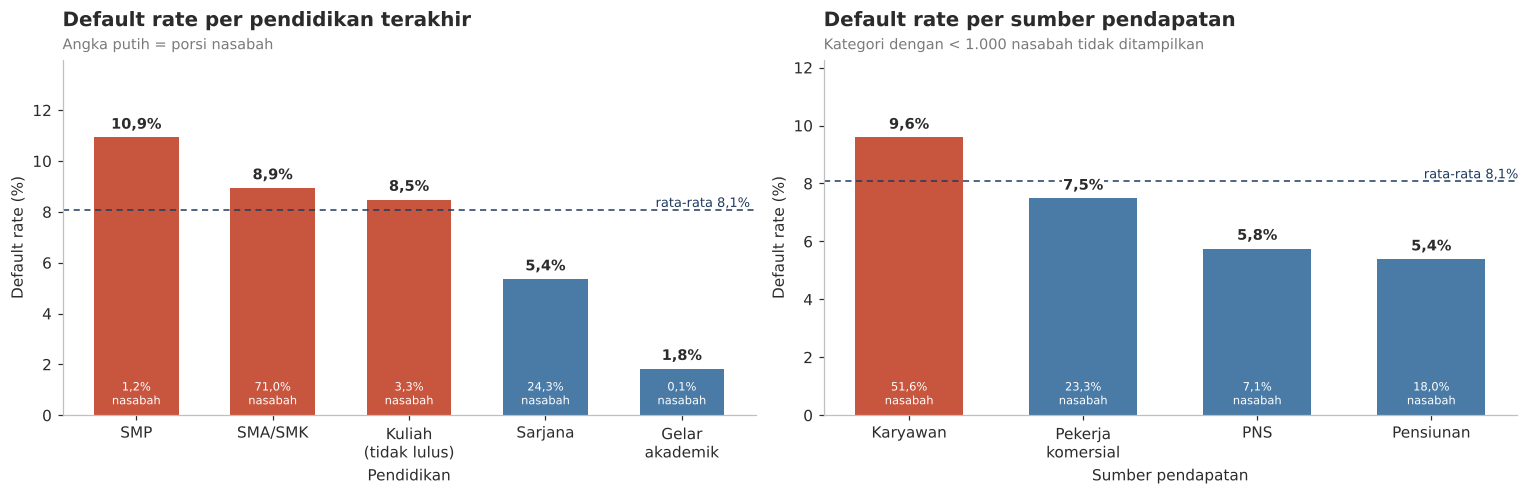

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
edu_map = {'Lower secondary': 'SMP', 'Secondary / secondary special': 'SMA/SMK', 'Incomplete higher': 'Kuliah\n(tidak lulus)',
           'Higher education': 'Sarjana', 'Academic degree': 'Gelar\nakademik'}
t = segment_table(train.assign(EDU=train.NAME_EDUCATION_TYPE.map(edu_map)), 'EDU', order=list(edu_map.values()))
plot_rate(t, 'EDU', 'Default rate per pendidikan terakhir', 'Angka putih = porsi nasabah', 'Pendidikan', ax=axes[0])
inc_map = {'Working': 'Karyawan', 'Commercial associate': 'Pekerja\nkomersial', 'State servant': 'PNS', 'Pensioner': 'Pensiunan'}
t = segment_table(train.assign(INC=train.NAME_INCOME_TYPE.map(inc_map)), 'INC', order=list(inc_map.values()))
plot_rate(t, 'INC', 'Default rate per sumber pendapatan', 'Kategori dengan < 1.000 nasabah tidak ditampilkan', 'Sumber pendapatan', ax=axes[1])
finish()

**Yang terlihat:** default rate per pendidikan terakhir (kiri) dan sumber pendapatan (kanan).

**Cara membaca:** perhatikan dua hal sekaligus: tinggi batang (risiko) dan angka putih (porsi nasabah). Segmen menarik untuk bisnis adalah yang **batangnya rendah tetapi porsinya masih kecil**.

**Temuan:**
- **Pendidikan:** lulusan **SMA/SMK mendominasi (71% nasabah)** dengan default rate 8,9%. **Sarjana hanya 5,4%**, tetapi porsinya baru 24%.
- **Sumber pendapatan:** **PNS (5,8%) dan pensiunan (5,4%)** paling aman, tetapi **PNS hanya 7% nasabah**. Karyawan swasta, kelompok terbesar (52%), berisiko 9,6%.

**Action:** jalankan **campaign akuisisi tertarget** untuk segmen yang aman tetapi porsinya masih kecil, yaitu PNS, pensiunan, dan lulusan sarjana. Misalnya promo bunga khusus PNS/pensiunan melalui kerja sama dengan instansi atau dana pensiun.

#### Q10. Tempat tinggal dan mobilitas nasabah

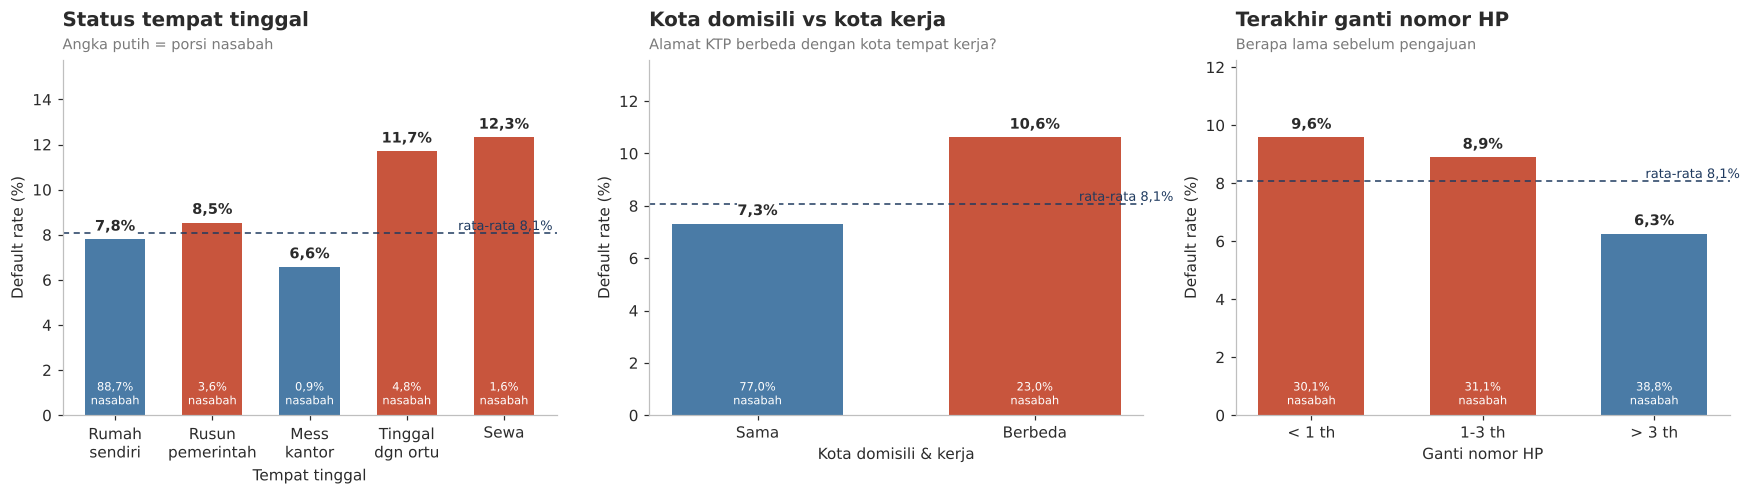

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
house_map = {'House / apartment': 'Rumah\nsendiri', 'Municipal apartment': 'Rusun\npemerintah', 'Office apartment': 'Mess\nkantor',
             'With parents': 'Tinggal\ndgn ortu', 'Rented apartment': 'Sewa'}
t = segment_table(train.assign(H=train.NAME_HOUSING_TYPE.map(house_map)), 'H', order=list(house_map.values()))
plot_rate(t, 'H', 'Status tempat tinggal', 'Angka putih = porsi nasabah', 'Tempat tinggal', ax=axes[0])
t = segment_table(train.assign(W=train.REG_CITY_NOT_WORK_CITY.map({0: 'Sama', 1: 'Berbeda'})), 'W', order=['Sama', 'Berbeda'])
plot_rate(t, 'W', 'Kota domisili vs kota kerja', 'Alamat KTP berbeda dengan kota tempat kerja?', 'Kota domisili & kerja', ax=axes[1])
ph_order = ['< 1 th', '1-3 th', '> 3 th']
train['PHONE_G'] = pd.cut(train.PHONE_CHANGE_YEARS, [-0.01, 1, 3, 50], labels=ph_order)
t = segment_table(train, 'PHONE_G', order=ph_order)
plot_rate(t, 'PHONE_G', 'Terakhir ganti nomor HP', 'Berapa lama sebelum pengajuan', 'Ganti nomor HP', ax=axes[2])
finish()

**Yang terlihat:** tiga indikator stabilitas: status tempat tinggal, apakah kota domisili sama dengan kota kerja, dan kapan nasabah terakhir mengganti nomor HP.

**Cara membaca:** di setiap grafik, bandingkan batang merah (di atas rata-rata) dengan batang biru (di bawah rata-rata). Angka putih = porsi nasabah.

**Temuan:** nasabah yang **kurang "menetap"** lebih berisiko:
- **Menyewa** (12,3%) dan **tinggal dengan orang tua** (11,7%) jauh di atas pemilik rumah (7,8%).
- **Kota domisili ≠ kota kerja** (23% nasabah): 10,6% vs 7,3%.
- **Ganti nomor HP dalam 1 tahun terakhir**: ±9,6%, sedangkan > 3 tahun hanya 6,3%. Nomor HP yang sering berganti juga **menyulitkan penagihan**.

**Action:**
1. Tambahkan **indikator stabilitas** (status rumah, kesesuaian alamat, umur nomor HP) ke *checklist* verifikasi.
2. Untuk nasabah yang baru ganti nomor, lakukan **verifikasi nomor HP + kontak darurat** sebelum pencairan.

### D. Riwayat & Beban Utang

#### Q11. Apakah riwayat di Home Credit memprediksi perilaku? (H6)

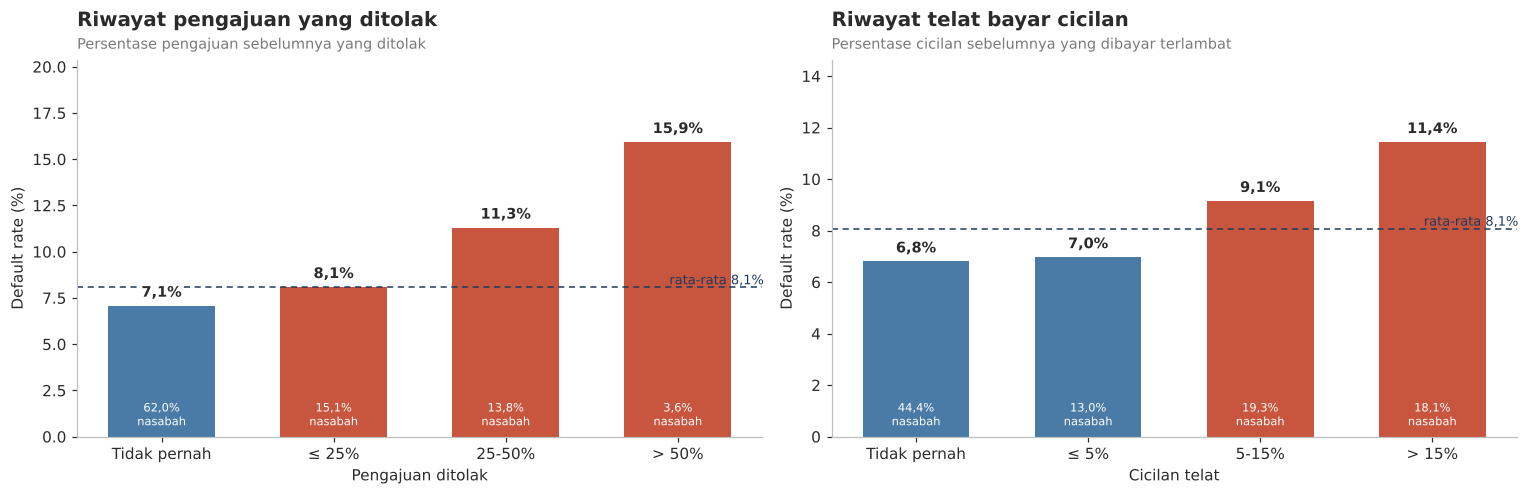

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
train['PREV_REFUSED_G'] = pd.cut(train.PREV_REFUSED_RATE, [-0.01, 0, 0.25, 0.5, 1],
                                 labels=['Tidak pernah', '≤ 25%', '25-50%', '> 50%'])
plot_rate(segment_table(train, 'PREV_REFUSED_G'), 'PREV_REFUSED_G', 'Riwayat pengajuan yang ditolak',
          'Persentase pengajuan sebelumnya yang ditolak', 'Pengajuan ditolak', ax=axes[0])
train['LATE_G'] = pd.cut(train.INST_LATE_RATE, [-0.01, 0, 0.05, 0.15, 1], labels=['Tidak pernah', '≤ 5%', '5-15%', '> 15%'])
plot_rate(segment_table(train, 'LATE_G'), 'LATE_G', 'Riwayat telat bayar cicilan',
          'Persentase cicilan sebelumnya yang dibayar terlambat', 'Cicilan telat', ax=axes[1])
finish()

**Yang terlihat:** default rate menurut riwayat nasabah di Home Credit: seberapa sering pengajuannya ditolak (kiri) dan seberapa sering telat membayar cicilan (kanan).

**Cara membaca:** dari kiri ke kanan, riwayat makin buruk. Jika batang makin tinggi ke kanan, riwayat buruk terbukti menaikkan risiko.

**Temuan:** **perilaku masa lalu memprediksi perilaku masa depan.**
- Nasabah yang **> 50% pengajuannya pernah ditolak** gagal bayar **15,9%** (2× rata-rata).
- Nasabah yang **> 15% cicilannya pernah telat** (18% nasabah) gagal bayar **11,4%**, sedangkan yang tidak pernah telat hanya **6,8%**.

**Action:**
1. **Fast-track approval** (proses cepat, limit lebih tinggi) untuk nasabah lama yang **selalu tepat waktu**. Ini memberi penghargaan atas perilaku baik sekaligus meningkatkan loyalitas.
2. Riwayat telat bayar > 15% menjadi **pemicu review manual**.

#### Q12. Beban utang di lembaga lain (Credit Bureau)

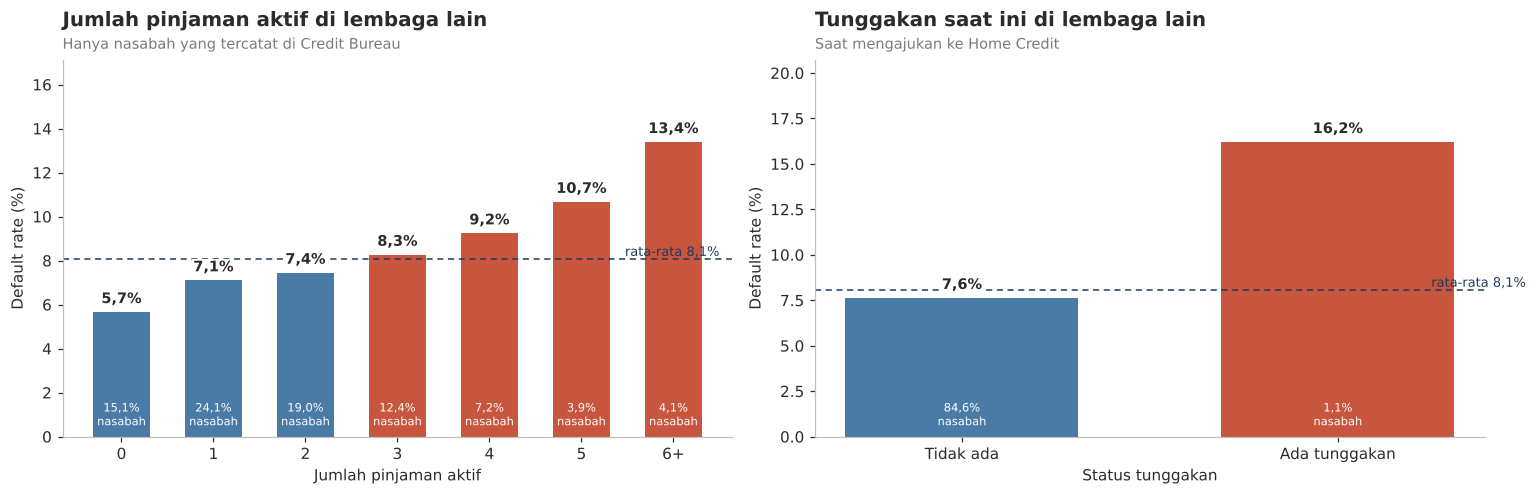

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
train['ACT_G'] = train.BUREAU_ACTIVE_CNT.clip(upper=6).map(lambda v: '6+' if v == 6 else (str(int(v)) if pd.notna(v) else np.nan))
plot_rate(segment_table(train, 'ACT_G', order=['0', '1', '2', '3', '4', '5', '6+']), 'ACT_G',
          'Jumlah pinjaman aktif di lembaga lain', 'Hanya nasabah yang tercatat di Credit Bureau', 'Jumlah pinjaman aktif', ax=axes[0])
train['OVD_G'] = pd.Series(np.where(train.BUREAU_OVERDUE_SUM > 0, 'Ada tunggakan', 'Tidak ada'), index=train.index).where(train.BUREAU_CNT.notna())
plot_rate(segment_table(train, 'OVD_G', order=['Tidak ada', 'Ada tunggakan']), 'OVD_G',
          'Tunggakan saat ini di lembaga lain', 'Saat mengajukan ke Home Credit', 'Status tunggakan', ax=axes[1])
finish()

**Yang terlihat:** default rate menurut jumlah pinjaman yang masih berjalan di lembaga keuangan lain (kiri) dan apakah nasabah sedang menunggak di sana (kanan).

**Cara membaca:** grafik kiri, perhatikan pola naiknya batang dari 0 ke 6+ pinjaman. Grafik kanan, bandingkan dua batang. Angka putih = porsi dari **seluruh** nasabah (nasabah tanpa riwayat bureau tidak ditampilkan).

**Temuan:** tanda **utang menumpuk** (*over-indebtedness*):
- Risiko naik **bertahap** seiring jumlah pinjaman aktif: dari **5,7%** (0 pinjaman) ke **13,4%** (6+ pinjaman), lebih dari 2× lipat.
- Nasabah yang **sedang menunggak** di lembaga lain gagal bayar **16,2%** (2× rata-rata). Jumlahnya hanya ±1%, tetapi sinyalnya sangat kuat.

**Action:**
1. **Wajibkan pengecekan Credit Bureau (SLIK OJK)** sebelum persetujuan, lalu masukkan hasilnya ke model.
2. **Bukan langsung ditolak**, karena mayoritas dari mereka tetap lancar (lihat Bagian 5). Sesuaikan **besar pinjamannya**: turunkan limit atau minta uang muka lebih besar untuk nasabah yang sedang menunggak atau punya 5+ pinjaman aktif.

#### Q13. Pemakaian kartu kredit Home Credit

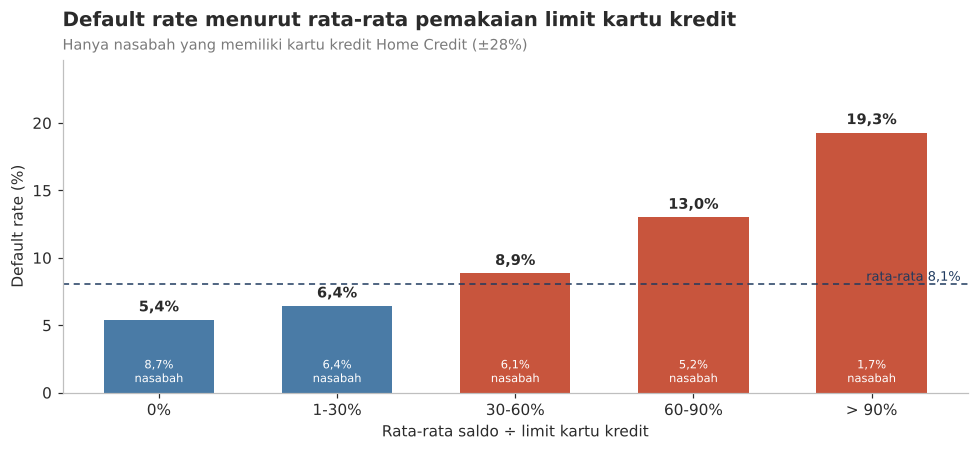

In [35]:
lbl = ['0%', '1-30%', '30-60%', '60-90%', '> 90%']
train['CCU_G'] = pd.cut(train.CC_UTILIZATION_MEAN, [-1, 0, 0.3, 0.6, 0.9, 100], labels=lbl)
t = segment_table(train, 'CCU_G', order=lbl)
plot_rate(t, 'CCU_G', 'Default rate menurut rata-rata pemakaian limit kartu kredit',
          'Hanya nasabah yang memiliki kartu kredit Home Credit (±28%)', 'Rata-rata saldo ÷ limit kartu kredit'); finish()

**Yang terlihat:** default rate menurut seberapa penuh nasabah memakai limit kartu kreditnya (*utilization rate*).

**Cara membaca:** utilisasi 90% = rata-rata saldo terpakai 90% dari limit. Angka putih = porsi dari **seluruh** nasabah.

**Temuan:** risiko naik tajam seiring pemakaian limit. Nasabah yang **hampir selalu memakai limit penuh (> 90%) gagal bayar 19,3%**, hampir **2,4× rata-rata** dan **3,6× lipat** dari yang tidak memakai (5,4%). Limit yang selalu penuh menandakan nasabah **bergantung pada utang** untuk kebutuhan sehari-hari.

**Action:**
1. Jadikan utilisasi > 90% **sinyal peringatan dini (*early warning*)** bagi nasabah aktif: tunda kenaikan limit dan tawarkan restrukturisasi/edukasi keuangan sebelum macet.
2. Jangan menawarkan pinjaman tambahan (*cross-sell*) ke nasabah dengan utilisasi > 90%.

#### Q14. Apakah nasabah tanpa riwayat kredit (*thin-file*) lebih berisiko?

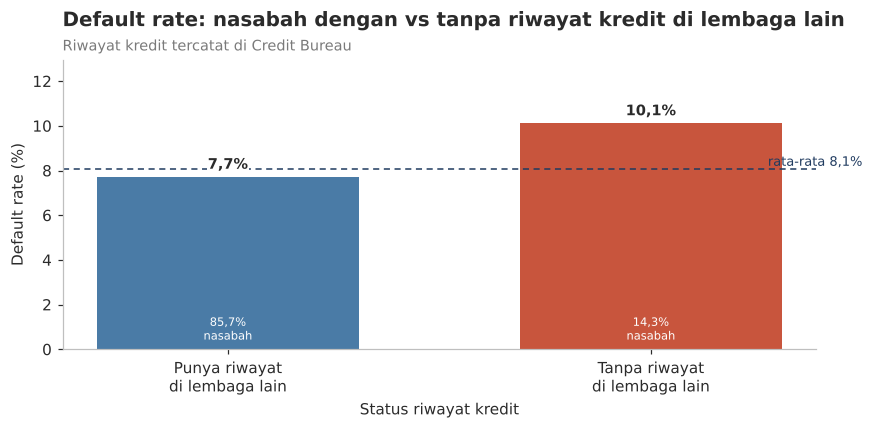

In [36]:
train['BUREAU_STATUS'] = np.where(train.BUREAU_CNT.isna(), 'Tanpa riwayat\ndi lembaga lain', 'Punya riwayat\ndi lembaga lain')
t = segment_table(train, 'BUREAU_STATUS')
plot_rate(t, 'BUREAU_STATUS', 'Default rate: nasabah dengan vs tanpa riwayat kredit di lembaga lain',
          'Riwayat kredit tercatat di Credit Bureau', 'Status riwayat kredit', figsize=(8, 4)); finish()

**Yang terlihat:** perbandingan nasabah yang punya dan tidak punya catatan kredit di lembaga lain.

**Cara membaca:** bandingkan tinggi kedua batang terhadap garis rata-rata 8,1%. Angka putih = porsi nasabah.

**Temuan:** **14% nasabah tidak punya riwayat kredit sama sekali**, dan default rate-nya lebih tinggi (**10,1%** vs 7,7%). Inilah segmen *unbanked*, pasar inti dan misi Home Credit.

**Action:** jangan menolak segmen ini secara otomatis karena "tidak ada data". Nilai mereka dengan **data alternatif** (skor eksternal, stabilitas pekerjaan dan tempat tinggal, pola pengajuan). Di sinilah **model machine learning paling bernilai**.

#### Q15. Apakah lingkungan sosial nasabah memberi sinyal risiko?

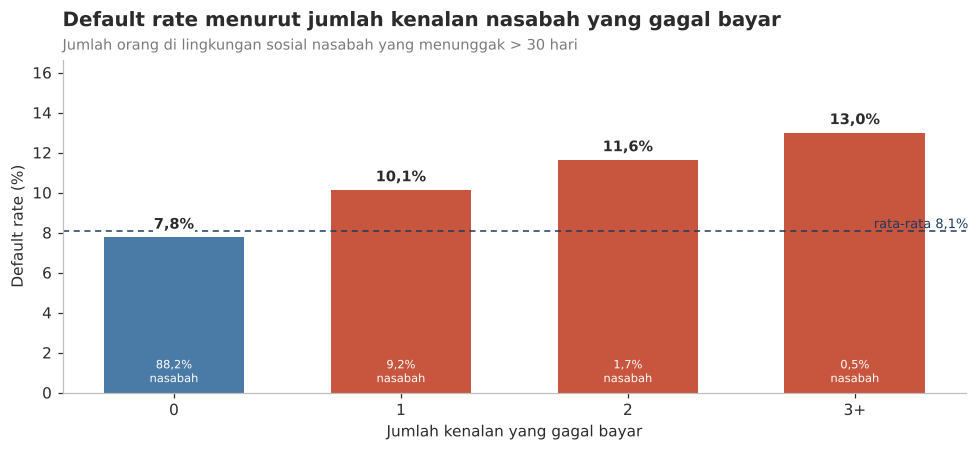

In [37]:
train['SOC_G'] = train.DEF_30_CNT_SOCIAL_CIRCLE.clip(upper=3).map(lambda v: '3+' if v == 3 else (str(int(v)) if pd.notna(v) else np.nan))
t = segment_table(train, 'SOC_G', order=['0', '1', '2', '3+'])
plot_rate(t, 'SOC_G', 'Default rate menurut jumlah kenalan nasabah yang gagal bayar',
          'Jumlah orang di lingkungan sosial nasabah yang menunggak > 30 hari', 'Jumlah kenalan yang gagal bayar'); finish()

**Yang terlihat:** default rate menurut berapa banyak orang di lingkungan sosial nasabah (kontak darurat, keluarga, rekan) yang juga pernah menunggak.

**Cara membaca:** dari kiri ke kanan, makin banyak kenalan yang gagal bayar. Perhatikan juga angka putih: kelompok 2 dan 3+ porsinya sangat kecil.

**Temuan:** makin banyak kenalan yang gagal bayar, makin tinggi risikonya: **7,8%** (tidak ada) → **10,1%** (1 orang) → **13,0%** (3+ orang). Lingkungan sosial mencerminkan kondisi ekonomi dan norma membayar di sekitar nasabah.

**Action:** dipakai **sebagai fitur model saja**, bukan alasan tunggal untuk menolak. Menolak seseorang karena perilaku orang lain berisiko tidak adil. Porsi nasabah dengan 2+ kenalan gagal bayar juga kecil (±2%).

### E. Wilayah & Produk

#### Q16. Wilayah mana yang berisiko? (H7)

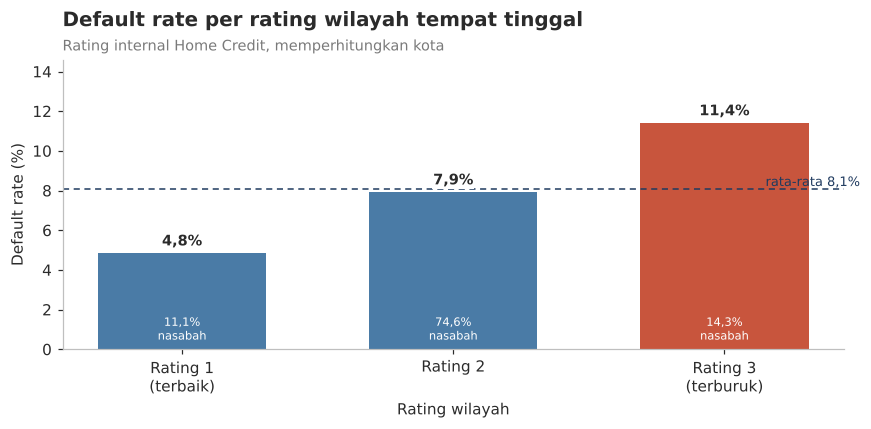

In [38]:
t = segment_table(train.assign(R=train.REGION_RATING_CLIENT_W_CITY.map({1: 'Rating 1\n(terbaik)', 2: 'Rating 2', 3: 'Rating 3\n(terburuk)'})),
                  'R', order=['Rating 1\n(terbaik)', 'Rating 2', 'Rating 3\n(terburuk)'])
plot_rate(t, 'R', 'Default rate per rating wilayah tempat tinggal', 'Rating internal Home Credit, memperhitungkan kota', 'Rating wilayah', figsize=(8, 4)); finish()

**Yang terlihat:** default rate menurut rating wilayah tempat tinggal nasabah (penilaian internal Home Credit).

**Cara membaca:** rating 1 = wilayah terbaik, rating 3 = terburuk. Batang merah = di atas rata-rata 8,1%.

**Temuan:** wilayah **rating 3** gagal bayar **11,4%**, lebih dari **2× wilayah rating 1** (4,8%). Mayoritas nasabah (75%) ada di wilayah rating 2.

**Action:** syarat **uang muka lebih tinggi** di wilayah rating 3, dan **perluas pemasaran** di wilayah rating 1 yang porsinya baru 11%.

#### Q17. Jenis kontrak dan gender

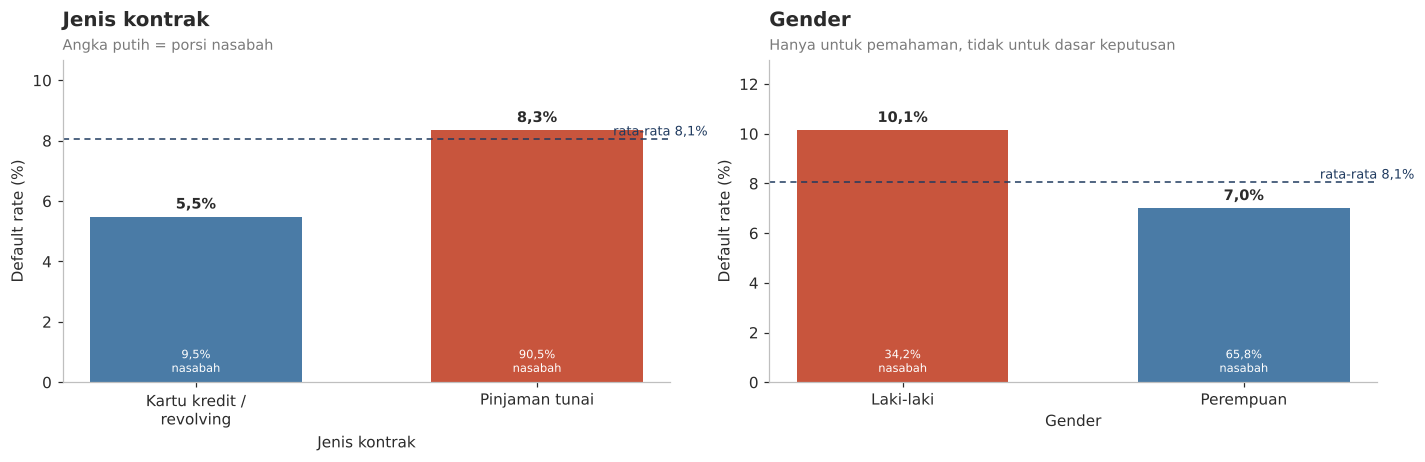

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
t = segment_table(train.assign(K=train.NAME_CONTRACT_TYPE.map({'Cash loans': 'Pinjaman tunai', 'Revolving loans': 'Kartu kredit /\nrevolving'})), 'K')
plot_rate(t, 'K', 'Jenis kontrak', 'Angka putih = porsi nasabah', 'Jenis kontrak', ax=axes[0])
t = segment_table(train.assign(G=train.CODE_GENDER.map({'F': 'Perempuan', 'M': 'Laki-laki'})), 'G')
plot_rate(t, 'G', 'Gender', 'Hanya untuk pemahaman, tidak untuk dasar keputusan', 'Gender', ax=axes[1])
finish()

**Yang terlihat:** default rate menurut jenis produk (kiri) dan gender (kanan).

**Cara membaca:** bandingkan tinggi batang terhadap garis rata-rata 8,1%. Angka putih = porsi nasabah.

**Temuan:**
- **Pinjaman tunai** (90% nasabah) lebih berisiko (8,3%) dibanding **revolving** (5,5%). Ini penting karena data test hampir seluruhnya pinjaman tunai.
- **Laki-laki** gagal bayar 10,1% vs **perempuan** 7,0%.

**Action & catatan etika:** gender **tidak boleh** menjadi dasar penolakan. Prinsip perlindungan konsumen sektor jasa keuangan mewajibkan perlakuan yang adil dan tidak diskriminatif. Di NB 04, model akan diuji **dengan dan tanpa** fitur gender, dan versi tanpa gender dipilih jika performanya setara.

## 5. Apakah aturan sederhana sudah cukup? (Justifikasi modeling)

Sebelum membuat model, kita uji dulu kebijakan **berbasis aturan** (*rule-based*) dari temuan di atas, misalnya "tolak semua nasabah usia < 25". Setiap aturan dinilai dengan metrik dari NB 01:
- **Recall**: dari seluruh calon gagal bayar, berapa persen yang berhasil ditolak
- **Precision**: dari seluruh nasabah yang ditolak, berapa persen yang memang calon gagal bayar
- **F2**: gabungan recall dan precision, dengan recall diberi bobot lebih
- **Total biaya** = kerugian dari gagal bayar yang lolos (pinjaman × LGD 45%) **+** keuntungan yang hilang dari nasabah baik yang ikut ditolak (margin bunga 13,6%), sesuai perhitungan di NB 01

In [40]:
LGD, NIM = 0.45, 0.136
tenor_thn = (train.AMT_CREDIT / train.AMT_ANNUITY) / 12
cost_fn = train.AMT_CREDIT * LGD
cost_fp = train.AMT_CREDIT / 2 * NIM * tenor_thn
y = train.TARGET.values

def evaluate_rule(reject_mask, name):
    reject = reject_mask.fillna(False).values.astype(bool)
    tp = (reject & (y == 1)).sum(); fp = (reject & (y == 0)).sum(); fn = (~reject & (y == 1)).sum()
    recall = tp / (tp + fn); precision = tp / (tp + fp) if (tp + fp) else 0
    f2 = 5 * precision * recall / (4 * precision + recall) if (precision + recall) else 0
    total = cost_fn[~reject & (y == 1)].sum() + cost_fp[reject & (y == 0)].sum()
    return {'aturan': name, 'ditolak_%': reject.mean() * 100, 'recall': recall, 'precision': precision, 'F2': f2,
            'default_rate_disetujui_%': y[~reject].mean() * 100, 'total_biaya': total}

ext_p10 = train.EXT_SOURCE_MEAN.quantile(0.10)
rules = [
    (pd.Series(False, index=train.index),            'Setujui semua (kondisi saat ini)'),
    (train.EXT_SOURCE_MEAN < ext_p10,                'Tolak skor eksternal 10% terendah'),
    (train.CC_UTILIZATION_MEAN > 0.9,                'Tolak utilisasi kartu kredit > 90%'),
    (train.BUREAU_OVERDUE_SUM > 0,                   'Tolak yang menunggak di lembaga lain'),
    (train.AGE_YEARS < 25,                           'Tolak usia < 25 tahun'),
    (train.PREV_REFUSED_RATE > 0.5,                  'Tolak riwayat ditolak > 50%'),
    (train.REGION_RATING_CLIENT_W_CITY == 3,         'Tolak wilayah rating 3'),
    ((train.EXT_SOURCE_MEAN < ext_p10) | (train.AGE_YEARS < 25) | (train.REGION_RATING_CLIENT_W_CITY == 3),
                                                     'Gabungan: skor rendah ATAU muda ATAU wilayah 3'),
]
rule_res = pd.DataFrame([evaluate_rule(m, n) for m, n in rules])
rule_res['perubahan_biaya_%'] = (rule_res.total_biaya / rule_res.total_biaya.iloc[0] - 1) * 100
rule_res.round(3)

,aturan,ditolak_%,recall,precision,F2,default_rate_disetujui_%,total_biaya,perubahan_biaya_%
0,Setujui semua (kondisi saat ini),0.000,0.000,0.000,0.000,8.073,"6,231,083,377.275",0.000
1,Tolak skor eksternal 10% terendah,9.994,0.284,0.229,0.271,6.423,"6,205,016,100.609",-0.418
2,Tolak utilisasi kartu kredit > 90%,1.694,0.040,0.193,0.048,7.880,"6,314,366,700.387",1.337
3,Tolak yang menunggak di lembaga lain,1.084,0.022,0.162,0.026,7.984,"6,325,576,907.948",1.516
4,Tolak usia < 25 tahun,3.951,0.060,0.123,0.067,7.898,"6,503,594,572.108",4.373
5,Tolak riwayat ditolak > 50%,3.641,0.072,0.159,0.081,7.776,"6,515,519,853.046",4.565
6,Tolak wilayah rating 3,14.263,0.201,0.114,0.175,7.519,"8,158,520,488.277",30.933
7,Gabungan: skor rendah ATAU muda ATAU wilayah 3,24.163,0.431,0.144,0.308,6.053,"8,449,072,306.886",35.596


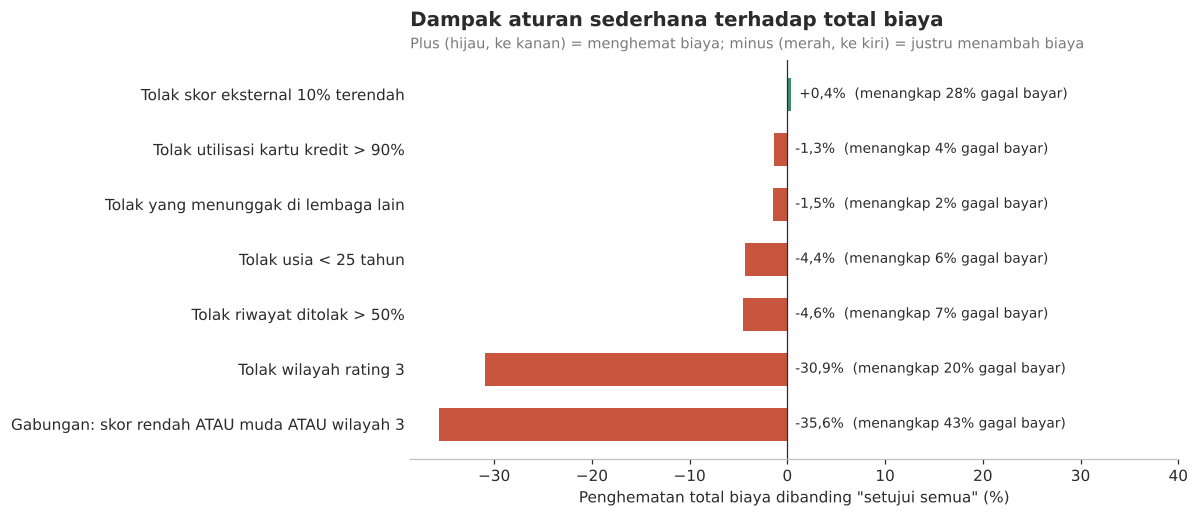

In [41]:
r = rule_res.iloc[1:].copy()
r['penghematan_%'] = -r['perubahan_biaya_%']                  # plus = hemat, minus = rugi
r = r.sort_values('penghematan_%')
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.barh(r.aturan, r['penghematan_%'], color=[GREEN if v > 0 else RED for v in r['penghematan_%']], height=0.6)
ax.axvline(0, color=INK, lw=0.8)
for i, (v, rc) in enumerate(zip(r['penghematan_%'], r.recall)):
    lbl = f'{"+" if v > 0 else ""}{fmt(v)}%  (menangkap {fmt(rc*100, 0)}% gagal bayar)'
    ax.text(max(v, 0) + 0.8, i, lbl, va='center', ha='left', fontsize=9)
ax.set_xlim(r['penghematan_%'].min() - 3, 40)
ax.set_xlabel('Penghematan total biaya dibanding "setujui semua" (%)'); ax.set_ylabel('')
ax.spines['left'].set_visible(False); ax.tick_params(axis='y', length=0)
ax.set_title('Dampak aturan sederhana terhadap total biaya'); subtitle(ax, 'Plus (hijau, ke kanan) = menghemat biaya; minus (merah, ke kiri) = justru menambah biaya')
finish()

**Yang terlihat:** perubahan total biaya (kerugian kredit + keuntungan yang hilang) jika Home Credit menerapkan setiap aturan, dibanding kondisi saat ini (semua disetujui).

**Cara membaca:** garis tengah (0%) adalah kondisi saat ini (semua pengajuan disetujui). Batang **hijau ke kanan (plus)** berarti aturan itu **menghemat** biaya; batang **merah ke kiri (minus)** berarti aturan itu justru **menambah** biaya. Angka dalam kurung adalah persentase calon gagal bayar yang berhasil ditolak (recall).

**Temuan:**
- **Hampir semua aturan justru menaikkan biaya.** Contohnya "tolak wilayah rating 3" menangkap 20% gagal bayar, tetapi ikut menolak puluhan ribu nasabah baik, sehingga biaya **bertambah ±31%** (penghematan -31%).
- **Hanya satu aturan yang menghemat biaya** (tolak skor eksternal 10% terendah), itu pun hanya **0,4%**, dan menangkap 28% gagal bayar.
- Bahkan menolak nasabah dengan sinyal sangat kuat (utilisasi kartu kredit > 90% atau sedang menunggak) **menaikkan biaya 1,3-1,5%**. Alasannya, 81-84% dari mereka **tetap membayar lancar**, sehingga keuntungan yang hilang lebih besar daripada kerugian yang dicegah.
- Menggabungkan aturan menaikkan recall ke 43%, tetapi menolak 24% pengajuan dan **biaya naik ±36%**.

**Kesimpulan: model machine learning dibutuhkan.** Risiko gagal bayar ditentukan oleh **kombinasi banyak faktor dengan bobot berbeda** (skor, usia, riwayat bayar, beban utang, stabilitas, wilayah). Aturan manual tidak mampu menimbang semuanya sekaligus. Model menggabungkan seluruh sinyal menjadi **satu skor risiko per nasabah**, lalu threshold dipilih untuk meminimalkan total biaya. Hasil aturan di atas menjadi **pembanding** model di NB 04.

## 6. Ringkasan Temuan

| # | Temuan | Default rate | Porsi nasabah | Kekuatan bukti |
|---|---|---|---|---|
| Q1-Q2 | Skor eksternal terendah (D1) vs tertinggi (D10) | 22,9% vs 2,0% | 10% / 10% | Sangat kuat (IV tertinggi) |
| Q2 | 20% nasabah berskor terendah menyumbang 46% gagal bayar | - | 20% | Sangat kuat |
| Q13 | Utilisasi kartu kredit > 90% | 19,3% | 1,7% | Sangat kuat |
| Q12 | Sedang menunggak di lembaga lain | 16,2% | 1,1% | Sangat kuat |
| Q11 | > 50% pengajuan sebelumnya ditolak | 15,9% | 3,6% | Kuat |
| Q12 | 6+ pinjaman aktif di lembaga lain | 13,4% | 4,1% | Kuat |
| Q3-Q4 | Usia 20-25 tahun (tetapi efeknya hilang jika skornya tinggi) | 12,3% | 4,0% | Kuat |
| Q10 | Menyewa / tinggal dengan orang tua | 11,7-12,3% | 6,4% | Kuat |
| Q6 | Pinjaman > 121% harga barang | 11,5% | 17,6% | Kuat |
| Q16 | Wilayah rating 3 | 11,4% | 14,3% | Kuat |
| Q7 | Masa kerja < 3 tahun | ±11% | 29% | Kuat |
| Q14 | Tanpa riwayat kredit di lembaga lain | 10,1% | 14,3% | Sedang |
| Q5 | Rasio cicilan/pendapatan tertinggi | ±8,6% | 20% | Lemah |
| Q8-Q9 | PNS / pensiunan / polisi / militer / bank (segmen aman) | ±5-6% | PNS hanya 7% | Kuat |

## 7. Top 2 Insight & Rekomendasi

### Insight 1: Hampir separuh gagal bayar berasal dari 20% nasabah berskor eksternal terendah
- Nasabah dengan skor eksternal terendah (10% terbawah) gagal bayar **22,9%**, hampir **3× rata-rata**. Yang tertinggi hanya **2,0%**.
- **20% nasabah berskor terendah menyumbang 46% dari seluruh gagal bayar.**
- Skor ini juga lebih menentukan daripada usia: nasabah muda berskor tinggi hanya berisiko ±4%, separuh dari rata-rata.

**Action:**
1. **Sistem jalur 3 tingkat berbasis skor:**
   - **Jalur cepat** (skor tinggi): persetujuan otomatis, proses lebih cepat
   - **Jalur normal**: proses standar
   - **Jalur review** (20% skor terendah): verifikasi dokumen dan wawancara oleh analis

   Dengan begitu analis fokus pada kelompok yang mengandung hampir separuh risiko.
2. **Hentikan penilaian berdasarkan usia.** Untuk nasabah muda berskor rendah, berikan **limit awal kecil yang naik bertahap** jika lancar.

### Insight 2: Tanda "utang menumpuk" adalah peringatan paling kuat, dan bisa dideteksi lebih awal
- Nasabah yang **memakai > 90% limit kartu kredit** gagal bayar **19,3%** (2,4× rata-rata).
- Nasabah yang **sedang menunggak di lembaga lain** gagal bayar **16,2%** (2× rata-rata).
- Risiko naik bertahap seiring jumlah pinjaman aktif: **5,7%** (0 pinjaman) ke **13,4%** (6+ pinjaman).
- Porsi kelompok ini kecil (1-4%), sehingga **tindakan tertarget tidak mengorbankan banyak nasabah baik**.

- **Catatan penting:** menolak mereka begitu saja justru **menaikkan total biaya 1,3-1,5%** (Bagian 5), karena 81-84% dari mereka tetap membayar lancar. Jadi yang tepat adalah **mengelola besaran risikonya**, bukan menolak.

**Action:**
1. **Wajib cek SLIK OJK sebelum persetujuan**, lalu jadikan jumlah pinjaman aktif dan status tunggakan sebagai **input model**.
2. **Sesuaikan limit, bukan menolak:** nasabah yang sedang menunggak atau punya 5+ pinjaman aktif mendapat limit lebih kecil atau syarat uang muka lebih besar, sehingga kerugian jika gagal bayar ikut mengecil.
3. **Early warning system** untuk nasabah aktif: utilisasi > 90% memicu penundaan kenaikan limit, larangan *cross-sell*, dan tawaran restrukturisasi atau edukasi keuangan **sebelum** nasabah macet.

### Rekomendasi pendukung
| Temuan | Action |
|---|---|
| Segmen aman tapi porsinya kecil (PNS, pensiunan, polisi/militer/bank, sarjana) | Campaign akuisisi & **kemitraan payroll** dengan instansi |
| Pinjaman > harga barang lebih berisiko; yang bayar DP lebih aman | **Insentif uang muka** (bunga lebih rendah jika DP ≥ 10%) |
| Nasabah lama yang selalu tepat waktu | **Fast-track** & limit lebih tinggi untuk loyalitas |
| Nasabah kurang menetap (sewa, sering ganti HP) | Verifikasi **nomor HP + kontak darurat** sebelum pencairan |
| Aturan sederhana justru menaikkan biaya | Gunakan **model machine learning** + threshold berbasis biaya (NB 04) |

## 8. Bekal untuk Notebook 04 (Modeling)

| Aspek | Keputusan dari EDA |
|---|---|
| **Cleaning** | Tabel 2.6 (dieksekusi dalam preprocessing pipeline) |
| **Fitur turunan yang terbukti berguna** | `EXT_SOURCE_MEAN`, `AGE_YEARS`, `EMPLOYED_YEARS`, `ANNUITY_INCOME`, `CREDIT_GOODS`, `PHONE_CHANGE_YEARS`, `IS_NOT_EMPLOYED`, `HAS_BUREAU`, `HAS_CC` |
| **Seleksi fitur** | Buang IV < 0,02; dari pasangan korelasi > 0,8 pertahankan satu |
| **Fairness** | Bandingkan model dengan & tanpa `CODE_GENDER` |
| **Imbalance** | `class_weight` / `scale_pos_weight`; evaluasi PR-AUC & F2 |
| **Outlier** | Log + batas persentil 99 untuk Logistic Regression |
| **Pembanding** | Hasil aturan sederhana di Bagian 5 |
| **Dashboard** | Dibuat setelah modeling (bersama Streamlit), sesuai keputusan alur proyek |
| **Evaluasi tambahan** | Performa khusus segmen cash loan (mayoritas data test) |

File pendukung: `data/processed/eda_information_value.csv`